# Medellín frente del terreno y pendiente. 

Análisis exploratorio



## Preparación

Rutas de los archivos y funciones de apoyo. La primera salida dice si cada archivo se encontró (OK) o no (FALTA). El cuaderno se abre desde la carpeta `codigo`; todas las rutas son relativas a ella.

In [4]:
import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

CARPETA = Path.cwd()
SALIDAS = CARPETA / "datos_salida"
AUX = SALIDAS / "auxiliares"
ENTRADAS = CARPETA / "datos_entrada"
RESPALDO = CARPETA / "respaldo_eda"

ARCHIVO_FINAL = SALIDAS / "medellin_pendientes_segmentos_dtm2021_v3.csv"
ARCHIVO_GPKG = ENTRADAS / "D2M_segmentos_para_pendiente.gpkg"
ARCHIVO_VALIDACIONES = SALIDAS / "medellin_pendientes_validaciones_v3.csv"
ARCHIVO_SENSIBILIDAD = SALIDAS / "medellin_pendientes_sensibilidad_v3.csv"
ARCHIVO_MANIFIESTO = SALIDAS / "medellin_pendientes_manifiesto_v3.json"
ARCHIVO_VERTICES = ENTRADAS / "igac_vertices_medellin.csv"
if not ARCHIVO_VERTICES.exists():
    ARCHIVO_VERTICES = CARPETA / "igac_vertices_medellin.csv"
ARCHIVO_V1 = RESPALDO / "medellin_pendientes_segmentos_dtm2021_v1.csv"
ARCHIVO_V2 = RESPALDO / "medellin_pendientes_segmentos_dtm2021_v2.csv"
ARCHIVO_30M = RESPALDO / "tarea5_tramos_medellin_20261008_135742.csv"
ARCHIVO_LISTA_REVISION = RESPALDO / "D3M_revision_street_view_med_sigma010.csv"
ARCHIVO_REVISION = RESPALDO / "revision_104_medellin_completada.csv"
ARCHIVO_RUTEO_CARROS = RESPALDO / "D4M_k50_12_carros.csv"
ARCHIVO_RUTEO_ESTRATOS = RESPALDO / "D4M_k50_por_terreno_y_banda.csv"
ARCHIVO_CASILLAS = RESPALDO / "D4M_muestra_casillas.csv"
ARCHIVO_PARES = RESPALDO / "D4M_muestra_pares_od.csv"
ARCHIVO_ASCENSO = AUX / "ascenso_linea_recta_medellin.csv"
ARCHIVO_ASCENSO_RESUMEN = AUX / "ascenso_linea_recta_medellin_resumen.csv"

SIGMA_Z, ANCHO = 0.539, 59.2          # sigma_z oficial desde la v3: RMSEz de los 9 vertices utiles
SIGMA_FICHA = 0.10                    # RMSEz declarado en la ficha del producto; queda como sensibilidad
COTA_LADERA_M = 1600.4199829101562     # mediana de las esquinas + 50 m (modulo del grafo, muestra del ruteo)
SHA_ESPERADO = "2aaba7230df0"
FUENTE_RUTEO = "D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735)"

AZUL, NARANJA, AQUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9,
})

for ruta in [ARCHIVO_FINAL, ARCHIVO_GPKG, ARCHIVO_VALIDACIONES, ARCHIVO_SENSIBILIDAD, ARCHIVO_MANIFIESTO,
             ARCHIVO_VERTICES, ARCHIVO_V1, ARCHIVO_V2, ARCHIVO_ASCENSO, ARCHIVO_30M, ARCHIVO_LISTA_REVISION, ARCHIVO_REVISION,
             ARCHIVO_RUTEO_CARROS, ARCHIVO_RUTEO_ESTRATOS, ARCHIVO_CASILLAS, ARCHIVO_PARES, AUX, RESPALDO]:
    print(f"{'OK   ' if ruta.exists() else 'FALTA'}  {ruta.relative_to(CARPETA)}")

OK     datos_salida\medellin_pendientes_segmentos_dtm2021_v3.csv
OK     datos_entrada\D2M_segmentos_para_pendiente.gpkg
OK     datos_salida\medellin_pendientes_validaciones_v3.csv
OK     datos_salida\medellin_pendientes_sensibilidad_v3.csv
OK     datos_salida\medellin_pendientes_manifiesto_v3.json
OK     datos_entrada\igac_vertices_medellin.csv
OK     respaldo_eda\medellin_pendientes_segmentos_dtm2021_v1.csv
OK     respaldo_eda\medellin_pendientes_segmentos_dtm2021_v2.csv
OK     datos_salida\auxiliares\ascenso_linea_recta_medellin.csv
OK     respaldo_eda\tarea5_tramos_medellin_20261008_135742.csv
OK     respaldo_eda\D3M_revision_street_view_med_sigma010.csv
OK     respaldo_eda\revision_104_medellin_completada.csv
OK     respaldo_eda\D4M_k50_12_carros.csv
OK     respaldo_eda\D4M_k50_por_terreno_y_banda.csv
OK     respaldo_eda\D4M_muestra_casillas.csv
OK     respaldo_eda\D4M_muestra_pares_od.csv
OK     datos_salida\auxiliares
OK     respaldo_eda


In [5]:
# Almacena las cifras obtenidas durante el proceso de análisis
CIFRAS = []

# Agrega una cifra al registro general para facilitar su consulta
def _guardar(seccion, dato, valor, nota):
    CIFRAS.append({"seccion": seccion, "dato": dato, "valor": valor, "nota": nota})

# Ajusta la precisión del valor, lo guarda en el registro
def mostrar(seccion, dato, valor, decimales=0, nota=""):
    """Muestra una cifra calculada con estos archivos."""
    d = max(decimales, 0)
    valor = round(float(valor), d + 6) + 0.0
    _guardar(seccion, dato, round(valor, d + 2), nota)
    print(f"{dato}: {valor:,.{d}f}" + (f"  ({nota})" if nota else ""))

# Registra y muestra valores que deben conservarse como texto
def mostrar_texto(seccion, dato, valor, nota=""):
    """Para huellas SHA y cifras escritas como texto."""
    _guardar(seccion, dato, str(valor), nota)
    print(f"{dato}: {valor}" + (f"  ({nota})" if nota else ""))

# Guarda y muestra cifras obtenidas de fuentes externas al análisis
def otra_fuente(seccion, dato, valor, fuente):
    """Cifra que viene de otro modulo o documento y no se recalcula con estos archivos."""
    _guardar(seccion, dato, valor, fuente)
    print(f"{dato}: {valor}  ({fuente})")

# Registra una cifra procedente de la tabla de otro módulo y la presenta con la cantidad de decimales definida 
def de_archivo(seccion, dato, valor, fuente, decimales=0):
    """Cifra que se lee de la tabla de otro modulo."""
    d = max(decimales, 0)
    _guardar(seccion, dato, round(float(valor), d + 2), fuente)
    print(f"{dato}: {float(valor):,.{d}f}  ({fuente})")

#Si algun dato no se puede calcular, por falta de algun archivo 
def pendiente(seccion, dato, motivo):
    _guardar(seccion, dato, None, motivo)
    print(f"[pendiente] {dato}: {motivo}")

# Estandariza los valores de una columna para identificar los registros que tienen asignado el valor booleano true
def verdadero(serie):
    return serie.astype(str).str.strip().str.lower().eq("true")

# Carga un archivo CSV detectando automáticamente el separador
def leer(ruta):
    return pd.read_csv(ruta, sep=None, engine="python", encoding="utf-8-sig")

# Calcula la raíz del error cuadrático medio de los valores recibidos
def rmse(r):
    r = pd.Series(r).dropna()
    return float(np.sqrt((r ** 2).mean()))

# Calcula la desviación absoluta mediana normalizada
def nmad(r):
    r = pd.Series(r).dropna()
    return float(1.4826 * np.median(np.abs(r - r.median())))

# Estima el error asociado a la pendiente según la longitud del tramo, la incertidumbre vertical y el ancho de correlación espacial
# Cuando no se define un ancho, se considera una correlación nula
def error_pendiente(L, sigma=SIGMA_Z, ancho=ANCHO):
    rho = 0.0 if ancho is None else np.exp(-np.asarray(L, float) / ancho)
    return 100 * np.sqrt(2 * sigma ** 2 * (1 - rho)) / np.asarray(L, float)

# Estima la variabilidad que introduce el ruido vertical en la pendiente acumulada, teniendo en cuenta la longitud del tramo y la cantidad
def ruido_acumulada(L, n, sigma=SIGMA_Z, ancho=ANCHO):
    p = np.asarray(L, float) / (np.asarray(n, float) - 1)
    sd = sigma * np.sqrt(2 * (1 - np.exp(-p / ancho)))
    return 100 * np.sqrt(2 / np.pi) * sd / p

# Calcula la proporción de casos observados y su intervalo de confianza mediante el método de Wilson
def wilson(k, n, z=1.959964):
    """Intervalo de Wilson (1927) al 95 %, en porcentaje."""
    p = k / n
    centro = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * p, 100 * (centro - margen), 100 * (centro + margen)

## Carga del archivo final

Primero se comprueba que el archivo sea el correcto: su SHA-256 debe empezar por `2aaba7230df0` (v3). La longitud, el nombre, la jerarquía, la marca de elevado y el paso a nivel se toman del GeoPackage del módulo del grafo.

Variables que se usan en todo el cuaderno: `df` (los 39.160 segmentos), `con` (los que tienen dato), `ext` (los que tienen `pendiente_extrema`) y `tramo_fisico` (el identificador sin FT o TF, que une los dos sentidos de una calle).

In [6]:
sha = hashlib.sha256(ARCHIVO_FINAL.read_bytes()).hexdigest()
print(f"SHA-256: {sha}")
print("Es el archivo entregado." if sha.startswith(SHA_ESPERADO) else "ATENCION: no es el archivo entregado.")

import geopandas as gpd
df = pd.read_csv(ARCHIVO_FINAL, float_precision="round_trip", low_memory=False)
seg = gpd.read_file(ARCHIVO_GPKG, layer="segmentos")
cols_red = ["segmento_id", "longitud_m", "nombre", "jerarquia", "es_elevado", "paso_nivel"]
df = df.merge(seg[cols_red], on="segmento_id", how="left", validate="one_to_one")
for col in ["distinta_de_cero_2sigma", "pendiente_extrema", "fuera_cobertura_mdt", "es_tunel"]:
    df[col] = verdadero(df[col])
df["es_elevado"] = df["es_elevado"].fillna(False).astype(bool)
partes = df["segmento_id"].str.rsplit("_", n=1)
df["tramo_fisico"], df["sentido"] = partes.str[0], partes.str[1]
df["neta_abs"] = df["pendiente_neta_pct"].abs()
fuera = df["fuera_cobertura_mdt"]
con = df[~fuera].copy()
ext = df[df["pendiente_extrema"]].copy()
print(f"{len(df):,} segmentos, {len(con):,} con dato, {len(ext):,} con pendiente extrema")

SHA-256: 2aaba7230df0845116775e5100d3bc9292f67c4041a33aed1082d28d69f68e5e
Es el archivo entregado.
39,160 segmentos, 39,158 con dato, 189 con pendiente extrema


4# 1. Caracterización del contexto

### Elevación y pendiente de la red

Se toman las elevaciones de los dos extremos de cada segmento con dato. La **mediana** deja la mitad de los valores por debajo y el **percentil 95** solo lo supera el 5 % más alto. La **pendiente neta** se describe en valor absoluto, porque el signo solo indica el sentido de recorrido.

In [7]:
mostrar("1", "segmentos dirigidos con dato", len(con))
z = pd.concat([con["z_inicio_m"], con["z_fin_m"]])
mostrar("1", "elevacion minima de la red (m)", z.min(), 1)
mostrar("1", "mediana de la elevacion (m)", z.median(), 1)
mostrar("1", "percentil 95 de la elevacion (m)", z.quantile(0.95), 1)
mostrar("1", "elevacion maxima de la red (m)", z.max(), 1)
a = con["neta_abs"]
mostrar("1", "mediana de |neta| (%)", a.median(), 2)
mostrar("1", "percentil 90 de |neta| (%)", a.quantile(0.90), 2)
mostrar("1", "percentil 99 de |neta| (%)", a.quantile(0.99), 2)

segmentos dirigidos con dato: 39,158
elevacion minima de la red (m): 1,436.8
mediana de la elevacion (m): 1,556.6
percentil 95 de la elevacion (m): 1,867.2
elevacion maxima de la red (m): 2,739.9
mediana de |neta| (%): 4.53
percentil 90 de |neta| (%): 16.85
percentil 99 de |neta| (%): 30.29


Se analizaron 39.158 segmentos dirigidos con dato. La red va de 1.436,8 a 2.739,9 m de altura, unos 1.300 m de diferencia. La mitad de los segmentos queda por debajo de 1.556,6 m y solo el 5 % pasa de 1.867,2 m, así que las partes más altas son pocas calles de ladera, la mitad de los segmentos tiene una pendiente neta menor a 4,53 %, pero uno de cada diez pasa de 16,85 % y el 1 % supera 30,29 %. En casi toda la ciudad la pendiente es suave, y las calles más empinadas son pocas pero de pendiente muy alta.

### Clasificación INVIAS

El Manual de diseño geométrico del INVIAS (2008, sección 1.2.2) da rangos de pendiente longitudinal por tipo de terreno: **Plano** menos de 3 %, **Ondulado** de 3 a menos de 6 %, **Montañoso** de 6 a 8 % y **Escarpado** más de 8 %. El escarpado se separa en sub-franjas para ver cuánto es pendiente de ladera plausible y cuánto supera 35 %.

In [8]:
CLASES = ["Plano", "Ondulado", "Montañoso", "Escarpado"]
cuenta = con["clasificacion_invias"].value_counts().reindex(CLASES)
for clase in CLASES:
    mostrar("1", f"segmentos {clase}", cuenta[clase])
    mostrar("1", f"% {clase}", 100 * cuenta[clase] / len(con), 2)
esc = con.loc[con["clasificacion_invias"] == "Escarpado", "neta_abs"]
for lo, hi in [(8, 15), (15, 25), (25, 35), (35, 1e9)]:
    etiqueta = f"más de {lo} %" if hi > 100 else f"entre {lo} y {hi} %"
    mostrar("1", f"escarpados con |neta| {etiqueta}", ((esc > lo) & (esc <= hi)).sum())

segmentos Plano: 15,604
% Plano: 39.85
segmentos Ondulado: 7,025
% Ondulado: 17.94
segmentos Montañoso: 3,390
% Montañoso: 8.66
segmentos Escarpado: 13,139
% Escarpado: 33.55
escarpados con |neta| entre 8 y 15 %: 7,925
escarpados con |neta| entre 15 y 25 %: 4,210
escarpados con |neta| entre 25 y 35 %: 819
escarpados con |neta| más de 35 %: 185


La red se reparte sobre todo entre dos extremos. El 39,85 % de los segmentos es plano y el 33,55 % es escarpado, mientras que ondulado y montañoso juntos solo suman el 26,6 %. En la ciudad hay muchas calles en el valle y muchas en ladera, y pocas en medio. De los 13.139 segmentos escarpados, el 60 % tiene entre 8 y 15 % de pendiente y solo 185 (1,4 %) pasan de 35 %.

### Concentración en la parte alta 

El GeoPackage no trae comuna ni barrio. La concentración se describe con la altura, usando la misma cota que el módulo del grafo usa para separar plano y ladera en la muestra del ruteo: 1.600,4 m (mediana de la altura de las esquinas, 1.550,4 m, más 50 m). Se aplica a la altura media de los dos extremos de cada segmento.

 Terreno escarpado y pendientes extremas por encima y por debajo de 1.600,4 m.

In [9]:
con["alto"] = (con["z_inicio_m"] + con["z_fin_m"]) / 2 > COTA_LADERA_M
ext["alto"] = (ext["z_inicio_m"] + ext["z_fin_m"]) / 2 > COTA_LADERA_M
tabla1 = con.groupby("alto").agg(segmentos=("segmento_id", "size"),
                                 plano_pct=("clasificacion_invias", lambda s: 100 * (s == "Plano").mean()),
                                 escarpado_pct=("clasificacion_invias", lambda s: 100 * (s == "Escarpado").mean()),
                                 mediana_neta_pct=("neta_abs", "median"))
tabla1["proporcion_pct"] = 100 * tabla1["segmentos"] / len(con)
tabla1["tramos_extremos"] = ext.groupby("alto")["tramo_fisico"].nunique()
tabla1.index = ["Hasta 1.600,4 m", "Mas de 1.600,4 m"]
display(tabla1.round(2))
esc_alto = con.loc[con["clasificacion_invias"] == "Escarpado", "alto"].mean()
mostrar("1", "escarpados por encima de la cota (%)", 100 * esc_alto, 1)
otra_fuente("1", "mediana de la altura de las esquinas (m)", "1.550,4", FUENTE_RUTEO + ", celda de la muestra")

,segmentos,plano_pct,escarpado_pct,mediana_neta_pct,proporcion_pct,tramos_extremos
"Hasta 1.600,4 m",23844,54.73,19.41,2.53,60.89,4
"Mas de 1.600,4 m",15314,16.67,55.58,9.22,39.11,91


escarpados por encima de la cota (%): 64.8
mediana de la altura de las esquinas (m): 1.550,4  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735), celda de la muestra)


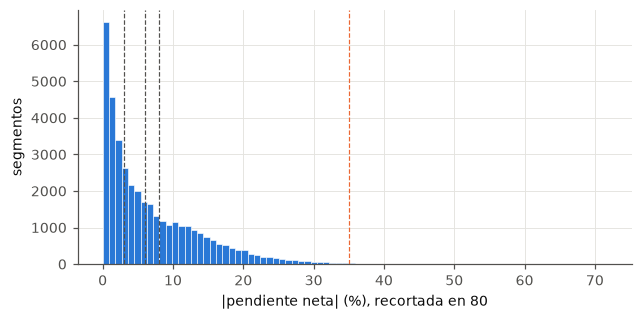

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.hist(a[a >= 0.01].clip(upper=80), bins=80, color=AZUL, edgecolor="white", linewidth=0.4)
for x0 in [3, 6, 8, 35]:
    ax.axvline(x0, color=NARANJA if x0 == 35 else TINTA_2, lw=0.8, ls="--")
ax.set_xlabel("|pendiente neta| (%), recortada en 80")
ax.set_ylabel("segmentos")
plt.show()

La distribución de la pendiente neta comienza alta y cae rápido. La barra más alta es la de 0 a 1 %, con unos 6.600 segmentos, y gran parte de la red queda antes del corte de 8 % de INVIAS. Después la cola se alarga hasta cerca de 30 %, y pasando 35 % casi no se ve porque los segmentos extremos son muy pocos. Con la cota de 1.600,4 m (la mediana de las esquinas, 1.550,4 m, más 50 m), el 60,89 % de los segmentos queda abajo. Allí el 54,73 % es plano y la pendiente mediana es de 2,53 %. Por encima está el 39,11 %, la mayoría escarpada (55,58 %), y la mediana sube a 9,22 %. Las pendientes extremas están casi todas arriba, 91 de los 95 tramos físicos extremos, igual que el 64,8 % de los segmentos escarpados.

# 2. Enfoque y diseño

### 2.1 El segmento dirigido y la simetría FT/TF

Un tramo físico es la calle sin importar el sentido, los de doble sentido aparecen dos veces. Como la pendiente es positiva cuando el tramo sube en el sentido de la fila, en un par FT/TF las dos netas deben sumar cero.

In [11]:
mostrar("2.1", "segmentos dirigidos", len(df))
mostrar("2.1", "tramos fisicos", df["tramo_fisico"].nunique())
por_tramo = df.groupby("tramo_fisico").size()
mostrar("2.1", "tramos con los dos sentidos", (por_tramo == 2).sum())
mostrar("2.1", "tramos con un solo sentido", (por_tramo == 1).sum())
pares = con[con["tramo_fisico"].duplicated(keep=False)].pivot(index="tramo_fisico", columns="sentido", values="pendiente_neta_pct").dropna()
mostrar("2.1", "pares con dato en los dos sentidos", len(pares))
mostrar_texto("2.1", "maximo de |neta FT + neta TF|", f"{(pares['FT'] + pares['TF']).abs().max():.1e}")

segmentos dirigidos: 39,160
tramos fisicos: 23,405
tramos con los dos sentidos: 15,755
tramos con un solo sentido: 7,650
pares con dato en los dos sentidos: 15,754
maximo de |neta FT + neta TF|: 2.5e-14


### 2.2 Pendiente neta y acumulada

La **acumulada** suma todas las subidas y bajadas del perfil. Cuando supera a la neta por más de 2 puntos, el tramo sube y baja por dentro.

In [12]:
dif = con["pendiente_acumulada_pct"] - con["neta_abs"]
mostrar("2.2", "acumulada mayor que la neta en mas de 2 pp", (dif > 2).sum())

acumulada mayor que la neta en mas de 2 pp: 1,717


En 1.717 segmentos (4,4 %), la pendiente acumulada supera a la neta en más de 2 puntos. En esos tramos la calle sube y baja por dentro de ella. En el resto de la red las dos medidas casi coinciden.

El piso de ruido mediano de la acumulada es de 2,20 %, muy cerca de esos 2 puntos. Por eso parte de esa diferencia puede ser ruido del DTM y no un cambio real del terreno.

### 2.3 Error de la pendiente según la longitud

El error sale de σz = 0,539 m (los 9 vértices) y de la correlación ρ = exp(−L/59,2): error = 100 × √(2 σz² (1 − ρ)) / L. Se compara con independencia (ρ = 0) y con el 0,10 m que declara la ficha.

In [13]:
dif_max = float(np.abs(error_pendiente(con["longitud_m"]) - con["error_pendiente_pct"]).max())
mostrar("2.3", "diferencia maxima formula vs error_pendiente_pct (pp)", dif_max, 12)
for largo in [10, 20, 50, 100]:
    mostrar("2.3", f"error a {largo} m (pp)", error_pendiente(largo), 2)
mostrar("2.3", "error a 10 m con independencia (pp)", error_pendiente(10, ancho=None), 2)
mostrar("2.3", "error a 10 m con el 0,10 de la ficha (pp)", error_pendiente(10, sigma=SIGMA_FICHA), 2)

diferencia maxima formula vs error_pendiente_pct (pp): 0.000000000000
error a 10 m (pp): 3.01
error a 20 m (pp): 2.04
error a 50 m (pp): 1.15
error a 100 m (pp): 0.69
error a 10 m con independencia (pp): 7.62
error a 10 m con el 0,10 de la ficha (pp): 0.56


La columna error_pendiente_pct del archivo coincide con la fórmula, la diferencia máxima es cero. El error baja a medida que el segmento es más largo, porque el mismo error de altura se reparte entre más distancia tenga. Es de 3,01 pp a 10 m, 2,04 pp a 20 m, 1,15 pp a 50 m y 0,69 pp a 100 m. La correlación entre las alturas de puntos cercanos importa, puesto que, Si los dos extremos se tomaran como independientes, el error a 10 m sería de 7,62 pp, más del doble. Con el 0,10 m que declara la ficha, bajaría a 0,56 pp.

# 3. Datos y fuentes de información

### 3.1 DTM-LiDAR Medellín 2021

La huella del .TIF y los parámetros se toman del manifiesto de la corrida. El RMSEz y el sistema que declara la ficha son datos de la ficha del producto (Subsecretaría de Catastro de Medellín, 2021), la tolerancia de un MDT1 es de la norma del IGAC (IGAC, 2022).

In [14]:
otra_fuente("3.1", "RMSEz declarado en la ficha del producto (m)", 0.10, "ficha del DTM-LiDAR Medellin 2021 (registro 440571dd")
otra_fuente("3.1", "RMSEz maximo de un MDT1, escala 1:1.000 (m)", 0.3, "IGAC, Resolucion 197 de 2022, tabla de exactitud vertical segun producto")
otra_fuente("3.1", "sistema declarado en la ficha", "EPSG:9377", "ficha del DTM-LiDAR Medellin 2021")
otra_fuente("3.1", "licencia", "CC BY-SA 4.0", "respuesta de la Subsecretaria de Catastro ")
if ARCHIVO_MANIFIESTO.exists():
    man = json.loads(ARCHIVO_MANIFIESTO.read_text(encoding="utf-8"))
    mostrar_texto("3.1", "SHA-256 del DTM (prefijo)", man["entradas"]["sha256_mdt"][:8])
    mostrar_texto("3.1", "sistemas de la red y del DTM", man["parametros"]["crs"])
else:
    pendiente("3.1", "SHA-256 del DTM", "falta el manifiesto: correr el programa principal")

RMSEz declarado en la ficha del producto (m): 0.1  (ficha del DTM-LiDAR Medellin 2021 (registro 440571dd)
RMSEz maximo de un MDT1, escala 1:1.000 (m): 0.3  (IGAC, Resolucion 197 de 2022, tabla de exactitud vertical segun producto)
sistema declarado en la ficha: EPSG:9377  (ficha del DTM-LiDAR Medellin 2021)
licencia: CC BY-SA 4.0  (respuesta de la Subsecretaria de Catastro )
SHA-256 del DTM (prefijo): bfd9709b
sistemas de la red y del DTM: EPSG:9377 -> EPSG:6257


### 3.1 Sistema de coordenadas del archivo

aux_crs_mdt.py transforma cada vértice útil del IGAC a EPSG:9377 (ficha) y a EPSG:6257 (archivo) y mira en cuál cae dentro del ráster.

Evidencia del sistema de coordenadas del DTM-LiDAR 2021.

In [15]:
ruta_crs = AUX / "aux_crs_mdt.csv"
if ruta_crs.exists():
    cr = leer(ruta_crs)
    cr["dentro_del_raster"] = verdadero(cr["dentro_del_raster"])
    t5 = cr.groupby("sistema").agg(vertices=("vertice", "size"), dentro=("dentro_del_raster", "sum"),
                                   x_min=("x", "min"), x_max=("x", "max"))
    display(t5)
    s6257 = cr[cr["sistema"].str.contains("6257")]
    s9377 = cr[cr["sistema"].str.contains("9377")]
    mostrar("3.1", "vertices dentro del raster con 6257", s6257["dentro_del_raster"].sum())
    mostrar("3.1", "vertices dentro del raster con 9377", s9377["dentro_del_raster"].sum())
    mostrar("3.1", "RMSEz en 6257 (m)", rmse(s6257["diferencia_m"]), 3)
    mostrar("3.1", "x minima de los vertices en 9377 (millones de m)", s9377["x"].min() / 1e6, 2)
    mostrar("3.1", "x maxima de los vertices en 9377 (millones de m)", s9377["x"].max() / 1e6, 2)
else:
    pendiente("3.1", "vertices dentro del raster en 6257 y en 9377", "falta datos_salida/auxiliares/aux_crs_mdt.csv")
otra_fuente("3.1", "limites del raster (E y N)", "816.953,59-846.021,59 E; 1.172.948,85-1.198.028,85 N", "aux_crs_mdt.py")

,vertices,dentro,x_min,x_max
sistema,,,,
archivo EPSG:6257,9,9,822775.4,837298.2
ficha EPSG:9377,9,0,4703740.2,4718185.1


vertices dentro del raster con 6257: 9
vertices dentro del raster con 9377: 0
RMSEz en 6257 (m): 0.539
x minima de los vertices en 9377 (millones de m): 4.70
x maxima de los vertices en 9377 (millones de m): 4.72
limites del raster (E y N): 816.953,59-846.021,59 E; 1.172.948,85-1.198.028,85 N  (aux_crs_mdt.py)


La ficha dice que el DTM está en EPSG:9377, pero las coordenadas del ráster no corresponden a ese sistema. El ráster va de 816.953,59 a 846.021,59 m en el eje este. Al pasar los 9 vértices del IGAC a EPSG:9377, su coordenada este queda entre 4,70 y 4,72 millones de metros, y ninguno cae dentro del ráster. Con EPSG:6257, que es el sistema que trae el archivo, caen los 9, y con ellos el RMSEz da 0,539 m.

### 3.3 Vértices de control del IGAC

Solo sirven los de coordenada **calculada** que siguen **materializados**. La NSSDA (FGDC, 1998) pide al menos 20 puntos de control.

 Vértices del IGAC en Medellín según tipo de coordenada y estado.

In [16]:
v = pd.read_csv(ARCHIVO_VERTICES, dtype={"vertice": str})
v["excluir"] = verdadero(v["excluir"])
calc = v["tipo_coordenada"] == "CALCULADA"
mostrar("3.3", "vertices del IGAC en Medellin", len(v))
mostrar("3.3", "con coordenada calculada", calc.sum())
mostrar("3.3", "calculados y materializados", (calc & (v["estado"] == "MATERIALIZADO")).sum())
mostrar("3.3", "calculados y destruidos", (calc & (v["estado"] == "DESTRUIDO")).sum())
mostrar("3.3", "con coordenada aproximada", (v["tipo_coordenada"] == "APROXIMADA").sum())
mostrar("3.3", "vertices utiles", (~v["excluir"]).sum())
otra_fuente("3.3", "minimo de puntos de control de la NSSDA", 20, "FGDC (1998)")
display(pd.crosstab(v["tipo_coordenada"], v["estado"], margins=True))

vertices del IGAC en Medellin: 29
con coordenada calculada: 12
calculados y materializados: 9
calculados y destruidos: 3
con coordenada aproximada: 17
vertices utiles: 9
minimo de puntos de control de la NSSDA: 20  (FGDC (1998))


estado,DESTRUIDO,MATERIALIZADO,All
tipo_coordenada,,,
APROXIMADA,0,17,17
CALCULADA,3,9,12
All,3,26,29


Hay 29 vértices del IGAC, 17 tienen solo coordenada aproximada, de los 12 con coordenada calculada, 3 están destruidos según el IGAC. Quedan 9 vértices útiles, menos de los 20 puntos de control que pide la NSSDA (FGDC, 1998). Por eso el RMSEz de 0,539 m se toma como una estimación

### 3.3 Primer intento con todos los vértices

Seis vértices dieron diferencias de entre 131 y 543 m en valor absoluto (cinco negativas y una positiva), los seis tienen coordenada aproximada.

In [17]:
va = leer(AUX / "aux_vertices_igac.csv")
va["excluir"] = verdadero(va["excluir"])
atip = va[va["observacion"].fillna("").str.contains("atipico")]
mostrar("3.3", "atipicos", len(atip))
mostrar("3.3", "atipicos con coordenada aproximada", (atip["tipo_coordenada"] == "APROXIMADA").sum())
mostrar("3.3", "RMSEz con los 29 vertices (m)", rmse(va["diferencia_m"]), 1)
mostrar("3.3", "menor diferencia absoluta de los atipicos (m)", atip["diferencia_m"].abs().min(), 0)
mostrar("3.3", "mayor diferencia absoluta de los atipicos (m)", atip["diferencia_m"].abs().max(), 0)
mostrar("3.3", "atipicos con el DTM por debajo del IGAC", (atip["diferencia_m"] < 0).sum())
display(atip[["vertice", "tipo_coordenada", "altura_igac_m", "z_mdt_m", "diferencia_m"]].round(1))

atipicos: 6
atipicos con coordenada aproximada: 6
RMSEz con los 29 vertices (m): 131.9
menor diferencia absoluta de los atipicos (m): 131
mayor diferencia absoluta de los atipicos (m): 543
atipicos con el DTM por debajo del IGAC: 5


,vertice,tipo_coordenada,altura_igac_m,z_mdt_m,diferencia_m
9,10-NW-3,APROXIMADA,2010.7,1879.8,-130.9
10,14-NW-3,APROXIMADA,2281.3,2129.5,-151.9
18,21-NW-3,APROXIMADA,2246.4,1932.2,-314.2
19,212-NW-2,APROXIMADA,1885.2,2101.7,216.4
21,25-NW-3,APROXIMADA,1980.0,1437.3,-542.7
23,7-NW-3,APROXIMADA,1755.8,1617.8,-138.1


Si se usaran los 29 vértices, el RMSEz daría 131,9 m, un valor alto. El problema está en 6 vértices atípicos, todos con coordenada aproximada, donde la altura del DTM se aleja de la del IGAC entre 131 y 543 m. En 5 de ellos el DTM queda por debajo. Diferencias de ese tamaño no son error del DTM, lo más probable es que la coordenada aproximada ponga el vértice en otro punto de la ladera, con otra altura. Por eso los vértices con coordenada aproximada se dejan por fuera del cálculo.

# 4. Métodos y herramientas

### 4.1 Elevaciones y alineación

aux_alineacion_mdt.py desplaza la red entre −8 y +8 m sobre el recorte del Olaya Herrera y mide la pendiente mediana del terreno bajo las vías.

desplazamiento del minimo en x (m): 0
desplazamiento del minimo en y (m): 0
pendiente mediana en el minimo (%): 3.68
pendiente mediana a -8 m en x (%): 5.27
segmentos y puntos de la prueba: 3.060 segmentos, 61.486 puntos  (encabezado de aux_alineacion_mdt.py)


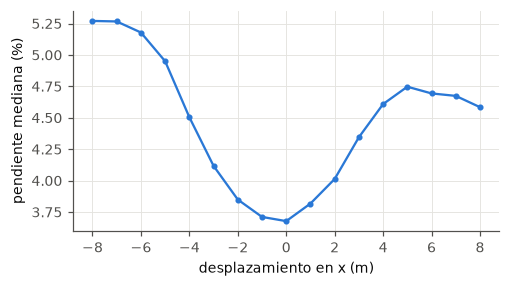

In [18]:
al = leer(AUX / "aux_alineacion_mdt.csv")
minimo = al.loc[al["pendiente_mediana_pct"].idxmin()]
mostrar("4.1", "desplazamiento del minimo en x (m)", minimo["dx_m"])
mostrar("4.1", "desplazamiento del minimo en y (m)", minimo["dy_m"])
mostrar("4.1", "pendiente mediana en el minimo (%)", minimo["pendiente_mediana_pct"], 2)
mostrar("4.1", "pendiente mediana a -8 m en x (%)", al.loc[(al["dx_m"] == -8) & (al["dy_m"] == 0), "pendiente_mediana_pct"].iloc[0], 2)
otra_fuente("4.1", "segmentos y puntos de la prueba", "3.060 segmentos, 61.486 puntos", "encabezado de aux_alineacion_mdt.py")
eje = al[al["dy_m"] == 0]
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(eje["dx_m"], eje["pendiente_mediana_pct"], color=AZUL, marker="o", ms=3)
ax.set_xlabel("desplazamiento en x (m)")
ax.set_ylabel("pendiente mediana (%)")
plt.show()

Se revisó si la red vial y el DTM están bien alineados. Se movió la red de 1 en 1 m, hasta 8 m en cada eje, y en cada posición se calculó la pendiente mediana de 3.060 segmentos (61.486 puntos). Cuando una calle se sale de su sitio, cae sobre andenes o fachadas, y la pendiente sube. La pendiente más baja, 3,68 %, se da sin mover la red, tanto en x como en y. Al mover la red 8 m en x sube a 5,27 %. Eso indica que la red y el DTM coinciden 

### 4.2 Exactitud vertical

Con los 9 vértices útiles se calcula la diferencia DTM − IGAC. El **RMSEz** es la raíz del promedio de las diferencias al cuadrado; el **NMAD** mide la dispersión sin dejarse llevar por valores atípicos (Höhle y Höhle, 2009). Con 9 puntos el resultado es una estimación
 Diferencia entre el DTM-LiDAR 2021 y la altura nivelada en los 9 vértices útiles.

In [19]:
util = va[~va["excluir"]].copy()
display(util[["vertice", "ano_calculo", "tipo_materializacion", "diferencia_m"]].round(2))
d = util["diferencia_m"]
mostrar("4.2", "RMSEz con los 9 utiles (m)", rmse(d), 3)
mostrar("4.2", "media (m)", d.mean(), 3)
mostrar("4.2", "desviacion estandar (m)", d.std(), 3)
mostrar("4.2", "mediana (m)", d.median(), 3)
mostrar("4.2", "NMAD (m)", nmad(d), 3)
mostrar("4.2", "3 desviaciones estandar (m)", 3 * d.std(), 2)
mostrar("4.2", "RMSEz sin 19-NW-3 (m)", rmse(d[util["vertice"] != "19-NW-3"]), 2)
mostrar("4.2", "sigma_z adoptado igual al RMSEz de los 9 (m)", round(rmse(d), 3), 3)
mostrar("4.2", "vertices excluidos", (va["excluir"]).sum())

,vertice,ano_calculo,tipo_materializacion,diferencia_m
0,05001008,2024,MOJON,-0.10
3,05001011,2024,MOJON,-0.46
5,05001013,2024,INCRUSTACION,0.27
6,05001014,2024,INCRUSTACION,-0.18
14,17-NW-3,1996,MOJON,0.06
17,19-NW-3,1996,INCRUSTACION,-1.50
20,22-NW-3,1996,MOJON,0.04
27,N8-NUEVO-TESORO-2,1965,MOJON,0.01
28,VOLADOR-18,2003,MOJON,-0.22


RMSEz con los 9 utiles (m): 0.539
media (m): -0.230
desviacion estandar (m): 0.517
mediana (m): -0.099
NMAD (m): 0.201
3 desviaciones estandar (m): 1.55
RMSEz sin 19-NW-3 (m): 0.22
sigma_z adoptado igual al RMSEz de los 9 (m): 0.539
vertices excluidos: 20


Con los 9 vértices , la diferencia entre el DTM y el IGAC va de −1,50 a 0,27 m, y el RMSEz da 0,539 m. La media es de −0,230 m, así que el DTM queda por debajo del IGAC. Casi todo el error lo pone un solo vértice, 19-NW-3, con −1,50 m. Sin él, el RMSEz baja a 0,22 m. Las medidas que no se dejan llevar por un valor extremo lo confirman, la mediana es de −0,099 m y el NMAD de 0,201 m. Aun así, 19-NW-3 no se excluyó, porque su diferencia no pasa de tres desviaciones estándar (1,55 m). Se adoptó σz = 0,539 m

### 4.2 Error por tipo de terreno

Como en Bogotá, la pendiente del terreno alrededor de cada vértice se mide con cuatro alturas a 10 m y el vértice se clasifica en plano (3 % o menos), inclinado (3 a 8 %) o ladera (más de 8 %) (aux_sigma_por_terreno.py). Con 9 vértices la tabla es descriptiva.

RMSEz del DTM-LiDAR 2021 por tipo de terreno alrededor del vértice.

In [20]:
ruta_terreno = AUX / "aux_sigma_por_terreno.csv"
if ruta_terreno.exists():
    st = leer(ruta_terreno)
    st = st[st["diferencia_m"].notna()]
    display(st.groupby("clase_terreno")["diferencia_m"].agg(vertices="count", rmsez_m=rmse).round(3))
    cuenta = st["clase_terreno"].value_counts()
    mostrar("4.2", "vertices en plano", cuenta.get("plano (<=3 %)", 0))
    mostrar("4.2", "vertices en inclinado", cuenta.get("inclinado (3-8 %)", 0))
    mostrar("4.2", "vertices en ladera", cuenta.get("ladera (>8 %)", 0))
    mostrar("4.2", "RMSEz en plano (m)", rmse(st.loc[st["clase_terreno"] == "plano (<=3 %)", "diferencia_m"]), 3)
    lad = st[st["clase_terreno"] == "ladera (>8 %)"]
    mostrar("4.2", "RMSEz en ladera (m)", rmse(lad["diferencia_m"]), 3)
    mostrar("4.2", "RMSEz en ladera sin 19-NW-3 (m)", rmse(lad.loc[lad["vertice"] != "19-NW-3", "diferencia_m"]), 2)
    mostrar("4.2", "pendiente del terreno en 19-NW-3 (%)", st.loc[st["vertice"] == "19-NW-3", "pendiente_terreno_pct"].iloc[0])
else:
    pendiente("4.2", "RMSEz por tipo de terreno", "falta datos_salida/auxiliares/aux_sigma_por_terreno.csv")
otra_fuente("4.2", "RMSEz en Bogota por terreno (m)", "0,44 (285), 0,56 (130) y 0,75 (81)", ".")

,vertices,rmsez_m
clase_terreno,,
ladera (>8 %),7,0.585
plano (<=3 %),2,0.329


vertices en plano: 2
vertices en inclinado: 0
vertices en ladera: 7
RMSEz en plano (m): 0.329
RMSEz en ladera (m): 0.585
RMSEz en ladera sin 19-NW-3 (m): 0.16
pendiente del terreno en 19-NW-3 (%): 52
RMSEz en Bogota por terreno (m): 0,44 (285), 0,56 (130) y 0,75 (81)  (.)


Separando los 9 vértices por terreno, 2 quedan en plano, 7 en ladera. El RMSEz da 0,329 m en plano y 0,585 m en ladera. Pero la diferencia la pone el 19-NW-3, que está en un terreno con 52 % de pendiente. Sin él, el RMSEz en ladera baja a 0,16 m. En Bogotá, con muchos más puntos, sí se ve que el error crece con la pendiente, 0,44 m (285 vértices), 0,56 m (130) y 0,75 m (81).

### 4.3 Correlación espacial del error

aux_ancho_correlacion.py busca ventanas planas de 200 × 200 m en el recorte del Olaya, toma una grilla cada 5 m, resta un plano y ajusta un variograma exponencial (Hugonnet et al., 2022). A = rango efectivo / 3; el adoptado es la mediana de las ventanas.

In [21]:
an = leer(AUX / "aux_ancho_correlacion.csv")
mostrar("4.3", "ventanas planas", len(an))
mostrar("4.3", "A minimo (m)", an["A_m"].min(), 1)
mostrar("4.3", "A maximo (m)", an["A_m"].max(), 1)
mostrar("4.3", "A mediano (m)", an["A_m"].median(), 1)
mostrar("4.3", "ventanas en el tope del ajuste", (an["rango_efectivo_m"] >= an["rango_efectivo_m"].max() - 1e-6).sum())
mostrar("4.3", "rango del tope (m)", an["rango_efectivo_m"].max(), 1)
otra_fuente("4.3", "A en Bogota (m)", 53.6, "documento de Bogota, 4.3")
display(an.round(2))

ventanas planas: 11
A minimo (m): 35.2
A maximo (m): 75.4
A mediano (m): 59.2
ventanas en el tope del ajuste: 4
rango del tope (m): 226.3
A en Bogota (m): 53.6  (documento de Bogota, 4.3)


,fila_px,columna_px,rango_efectivo_m,A_m,desv_residuo_m
0,560,1180,133.10,44.37,0.40
1,780,1140,133.64,44.55,0.50
2,1000,1100,177.68,59.23,0.57
3,1260,1040,204.68,68.23,0.41
4,1480,1000,226.27,75.42,0.32
5,1620,1220,105.69,35.23,0.24
6,1700,960,226.27,75.42,0.38
7,1920,920,226.27,75.42,0.37
8,2140,880,158.98,52.99,0.34
9,2360,840,226.27,75.42,0.40


Hasta qué distancia se parecen los errores de altura de dos puntos, se ajustó la correlación en 11 ventanas de terreno plano. El ancho de correlación A salió entre 35,2 y 75,4 m, y se tomó la mediana, 59,2 m, muy cerca de los 53,6 m de Bogotá. En 4 de las 11 ventanas el ajuste llegó al tope (rango de 226,3 m, A = 75,4 m), así que en ellas el ancho real podría ser mayor. Si fuera mayor, el error de la pendiente sería más bajo, de modo que 59,2 m no subestima el error.

### 4.4 Muestreo adaptativo

Con los dos extremos se calcula una pendiente preliminar: si es menor de 3 % se muestrea cada 50 m y si no cada 10 m. Los túneles se toman de boca a boca. Un segmento queda con solo 2 puntos si es plano y mide menos de 100 m, o si tiene pendiente y mide 20 m o menos.

In [22]:
no_tunel = con[~con["es_tunel"]]
plano = no_tunel["paso_muestreo_m"] == 50
dos = no_tunel["n_puntos_muestreados"] == 2
mostrar("4.4", "segmentos con paso de 50 m", plano.sum())
mostrar("4.4", "porcentaje con paso de 50 m", 100 * plano.sum() / len(con), 1)
mostrar("4.4", "segmentos con paso de 10 m", (no_tunel["paso_muestreo_m"] == 10).sum())
mostrar("4.4", "segmentos con 2 puntos (sin tuneles)", dos.sum())
mostrar("4.4", "  planos", (dos & plano).sum())
mostrar("4.4", "  con pendiente y 20 m o menos", (dos & ~plano).sum())
mostrar("4.4", "maximo de puntos de un perfil", con["n_puntos_muestreados"].max())

segmentos con paso de 50 m: 15,596
porcentaje con paso de 50 m: 39.8
segmentos con paso de 10 m: 23,532
segmentos con 2 puntos (sin tuneles): 13,430
  planos: 11,645
  con pendiente y 20 m o menos: 1,785
maximo de puntos de un perfil: 964


### 4.4 Efecto del paso de 50 m en los planos

aux_paso_muestreo.py vuelve a muestrear con 10 m los tramos planos del recorte del Olaya y compara la acumulada con la de 50 m. El ruido esperado con 10 m sirve de escala.

In [23]:
pm = leer(AUX / "aux_paso_muestreo.csv")
dp = pm["diferencia_pp"]
mostrar("4.4", "tramos planos en el Olaya", len(pm))
mostrar("4.4", "diferencia mediana (pp)", dp.median(), 2)
mostrar("4.4", "diferencia percentil 90 (pp)", dp.quantile(0.9), 2)
mostrar("4.4", "porcentaje con mas de 1 pp", 100 * (dp > 1).mean(), 1)
mostrar("4.4", "tramos con mas de 5 pp", (dp > 5).sum())
mostrar("4.4", "longitud minima de esos tramos (m)", pm.loc[dp > 5, "longitud_m"].min(), 0)
mostrar("4.4", "longitud maxima de esos tramos (m)", pm.loc[dp > 5, "longitud_m"].max(), 0)
mostrar("4.4", "tramos que pasan de 35 % con 10 m", (pm["acumulada_10m_pct"] > 35).sum())
mostrar("4.4", "ruido esperado con paso de 10 m (pp)", float(ruido_acumulada(10, 2)), 2)
mostrar("4.4", "ruido esperado con paso de 10 m y el 0,10 de la ficha (pp)", float(ruido_acumulada(10, 2, sigma=SIGMA_FICHA)), 2)

tramos planos en el Olaya: 1,522
diferencia mediana (pp): 0.05
diferencia percentil 90 (pp): 0.57
porcentaje con mas de 1 pp: 3.2
tramos con mas de 5 pp: 7
longitud minima de esos tramos (m): 28
longitud maxima de esos tramos (m): 42
tramos que pasan de 35 % con 10 m: 0
ruido esperado con paso de 10 m (pp): 2.40
ruido esperado con paso de 10 m y el 0,10 de la ficha (pp): 0.44


En los planos la acumulada se calcula con un paso de 50 m, se volvieron a muestrear con 10 m los 1.522 tramos planos del recorte del Olaya Herrera. El cambio es pequeño, la diferencia mediana es de 0,05 pp, el percentil 90 de 0,57 pp y solo el 3,2 % de los tramos cambia más de 1 pp. Los 7 tramos que cambian más de 5 pp son cortos, de 28 a 42 m, y ninguno pasa de 35 % con el paso de 10 m. Además, estas diferencias quedan por debajo del ruido que se espera con un paso de 10 m, 2,40 pp. 

### 4.5 Túneles

En un túnel el modelo mide la montaña: la pendiente se toma de boca a boca. Se marcan los tramos con túnel en el nombre y los sin nombre cuyos dos nodos pertenecen a tramos de túnel.

In [24]:
tun = df[df["es_tunel"]].copy()
por_nombre = tun["nombre"].fillna("").str.contains(r"t[uú]nel", case=False, regex=True)
mostrar("4.5", "filas con es_tunel", len(tun))
mostrar("4.5", "  por nombre", por_nombre.sum())
mostrar("4.5", "  sin nombre que cierran la cadena", (~por_nombre).sum())
occ = tun[tun["tramo_fisico"] == "MED_132113_0"]
mostrar("4.5", "Tunel de Occidente, |neta| (%)", occ["neta_abs"].max(), 2)
mostrar("4.5", "Tunel de Occidente, ganancia en el sentido de subida (m)", occ["ganancia_elevacion_m"].max(), 1)
mostrar("4.5", "MED_138418_0_FT, |neta| (%)", tun.loc[tun["segmento_id"] == "MED_138418_0_FT", "neta_abs"].iloc[0], 2)
mostrar("4.5", "MED_138419_0_FT, |neta| (%)", tun.loc[tun["segmento_id"] == "MED_138419_0_FT", "neta_abs"].iloc[0], 1)

filas con es_tunel: 30
  por nombre: 28
  sin nombre que cierran la cadena: 2
Tunel de Occidente, |neta| (%): 2.26
Tunel de Occidente, ganancia en el sentido de subida (m): 105.1
MED_138418_0_FT, |neta| (%): 42.47
MED_138419_0_FT, |neta| (%): 27.0


### 4.7 Diccionario de columnas

 Se comprueba que el archivo tenga las 19 columnas del contrato, en orden, con es_tunel al final.

In [25]:
COLUMNAS = ["segmento_id", "pendiente_neta_pct", "pendiente_acumulada_pct", "ganancia_elevacion_m", "perdida_elevacion_m",
            "z_inicio_m", "z_fin_m", "n_puntos_muestreados", "paso_muestreo_m", "clasificacion_invias", "error_pendiente_pct",
            "distinta_de_cero_2sigma", "ruido_acumulada_pct", "pendiente_extrema", "fuera_cobertura_mdt", "rho_correlacion",
            "ancho_correlacion_m", "sigma_z_m", "es_tunel"]
encabezado = pd.read_csv(ARCHIVO_FINAL, nrows=0).columns.tolist()
mostrar("4.7", "columnas del archivo", len(encabezado))
mostrar("4.7", "columnas en el orden del contrato", int(encabezado == COLUMNAS))
mostrar("4.7", "un solo sigma_z (m)", df["sigma_z_m"].unique()[0] if df["sigma_z_m"].nunique() == 1 else -1, 3)
mostrar("4.7", "un solo ancho (m)", df["ancho_correlacion_m"].unique()[0] if df["ancho_correlacion_m"].nunique() == 1 else -1, 1)

columnas del archivo: 19
columnas en el orden del contrato: 1
un solo sigma_z (m): 0.539
un solo ancho (m): 59.2


# 5. Estrategia de evaluación y verificación

### 5.2 Cumplimiento d

El programa principal aplica 20 validaciones antes de exportar. aux_verificar_contrato.py lee el CSV como texto

In [26]:
val = leer(ARCHIVO_VALIDACIONES)
mostrar("5.2", "validaciones del programa principal", len(val))
mostrar("5.2", "validaciones que pasan", verdadero(val["pasa"]).sum())
vc = leer(AUX / "aux_verificar_contrato.csv")
mostrar("5.2", "reglas de la verificacion independiente", len(vc))
mostrar("5.2", "reglas cumplidas", verdadero(vc["pasa"]).sum())

validaciones del programa principal: 20
validaciones que pasan: 20
reglas de la verificacion independiente: 18
reglas cumplidas: 18


### 5.5 Reproducibilidad

El SHA-256 del archivo debe ser el registrado. Las corridas que lo reprodujeron están en sus bitácoras.

In [27]:
mostrar_texto("5.5", "SHA-256 del archivo final (prefijo)", sha[:12])
otra_fuente("5.5", "tiempo de la corrida oficial de la v3", "1 min 12 s", "bitacora , Windows")
otra_fuente("5.5", "reproduccion de la v3 con el mismo SHA", " con el codigo final", "medellin_pendientes_bitacora_v3.log")

SHA-256 del archivo final (prefijo): 2aaba7230df0
tiempo de la corrida oficial de la v3: 1 min 12 s  (bitacora , Windows)
reproduccion de la v3 con el mismo SHA:  con el codigo final  (medellin_pendientes_bitacora_v3.log)


# 6. Consideraciones éticas y 7. Arquitectura


In [56]:
esperadas = ["medellin_pendientes_segmentos_dtm2021_v3.csv", "medellin_pendientes_segmentos_dtm2021_v3.csv.sha256",
             "medellin_pendientes_huellas_v3.json", "medellin_pendientes_manifiesto_v3.json",
             "medellin_pendientes_bitacora_v3.log", "medellin_pendientes_validaciones_v3.csv",
             "medellin_pendientes_sensibilidad_v3.csv"]
presentes = [n for n in esperadas if (SALIDAS / n).exists()]
for n in esperadas:
    print(f"{'OK   ' if n in presentes else 'FALTA'}  datos_salida/{n}")
mostrar("7", "salidas del programa principal presentes", len(presentes))
auxiliares = sorted(p.name for p in (CARPETA / "auxiliares").glob("aux_*.py"))
print(auxiliares)
mostrar("7", "programas auxiliares", len(auxiliares))

OK     datos_salida/medellin_pendientes_segmentos_dtm2021_v3.csv
OK     datos_salida/medellin_pendientes_segmentos_dtm2021_v3.csv.sha256
OK     datos_salida/medellin_pendientes_huellas_v3.json
OK     datos_salida/medellin_pendientes_manifiesto_v3.json
OK     datos_salida/medellin_pendientes_bitacora_v3.log
OK     datos_salida/medellin_pendientes_validaciones_v3.csv
OK     datos_salida/medellin_pendientes_sensibilidad_v3.csv
salidas del programa principal presentes: 7
['aux_alineacion_mdt.py', 'aux_ancho_correlacion.py', 'aux_ascenso_linea_recta_medellin.py', 'aux_comparacion_30m.py', 'aux_comparar_versiones.py', 'aux_crs_mdt.py', 'aux_paso_muestreo.py', 'aux_pendientes_extremas.py', 'aux_resolucion_srtm.py', 'aux_revision_street_view.py', 'aux_sigma_por_terreno.py', 'aux_tuneles.py', 'aux_verificar_contrato.py', 'aux_vertices_igac.py']
programas auxiliares: 14


# 8. Desarrollo técnico

### 8.2 Primer intento de σz

Con todos los vértices, el RMSEz es de 131,9 m (sección 3.3); con los 9 útiles, 0,539 m (sección 4.2). Son las cifras de la fila Vértices de contraste.

### 8.3 Efecto de los cambios de versión

De v1 a v2 las categorías deben ser idénticas y los números solo pueden diferir en el último dígito. De v2 a v3 (σz de 0,10 a 0,539 m) la pendiente debe ser idéntica y solo pueden cambiar las columnas que dependen de σz.

In [29]:
def leer_texto(ruta):
    return pd.read_csv(ruta, dtype=str, keep_default_na=False).set_index("segmento_id")

if ARCHIVO_V1.exists() and ARCHIVO_V2.exists():
    x, y = leer_texto(ARCHIVO_V1), leer_texto(ARCHIVO_V2)
    y = y.loc[x.index]
    categorias = ["clasificacion_invias", "distinta_de_cero_2sigma", "pendiente_extrema", "fuera_cobertura_mdt", "es_tunel"]
    mostrar("8.3", "filas con alguna categoria distinta", (x[categorias] != y[categorias]).any(axis=1).sum())

    def num(s):
        return s.map(lambda t: float(t) if t != "" else np.nan)

    for col in ["pendiente_neta_pct", "pendiente_acumulada_pct"]:
        mostrar("8.3", f"filas distintas en {col}", (x[col] != y[col]).sum())
        mostrar_texto("8.3", f"diferencia maxima en {col}", f"{(num(x[col]) - num(y[col])).abs().max():.1e}")
    mostrar("8.3", "filas distintas en z_inicio_m", (x["z_inicio_m"] != y["z_inicio_m"]).sum())
    dif_z = max((num(x[c]) - num(y[c])).abs().max() for c in ["z_inicio_m", "z_fin_m"])
    mostrar_texto("8.3", "diferencia maxima en alturas (m)", f"{dif_z:.1e}")
else:
    pendiente("8.3", "comparacion v1 y v2", "faltan la v1 o la v2 en respaldo_eda")

if ARCHIVO_V2.exists():
    x, y = leer_texto(ARCHIVO_V2), leer_texto(ARCHIVO_FINAL)
    y = y.loc[x.index]
    iguales = ["pendiente_neta_pct", "pendiente_acumulada_pct", "ganancia_elevacion_m", "perdida_elevacion_m", "z_inicio_m",
               "z_fin_m", "n_puntos_muestreados", "paso_muestreo_m", "clasificacion_invias", "pendiente_extrema",
               "fuera_cobertura_mdt", "rho_correlacion", "ancho_correlacion_m", "es_tunel"]
    mostrar("8.3", "v2 frente a v3: filas con alguna columna de pendiente distinta", (x[iguales] != y[iguales]).any(axis=1).sum())
    mostrar("8.3", "v2 frente a v3: segmentos que dejan de ser distinguibles de cero", ((x["distinta_de_cero_2sigma"] == "True") & (y["distinta_de_cero_2sigma"] == "False")).sum())
    mostrar("8.3", "v2 frente a v3: segmentos que pasan a ser distinguibles", ((x["distinta_de_cero_2sigma"] == "False") & (y["distinta_de_cero_2sigma"] == "True")).sum())
else:
    pendiente("8.3", "comparacion v2 y v3", "falta respaldo_eda/medellin_pendientes_segmentos_dtm2021_v2.csv")

filas con alguna categoria distinta: 0
filas distintas en pendiente_neta_pct: 7,742
diferencia maxima en pendiente_neta_pct: 7.1e-15
filas distintas en pendiente_acumulada_pct: 7,580
diferencia maxima en pendiente_acumulada_pct: 1.1e-13
filas distintas en z_inicio_m: 313
diferencia maxima en alturas (m): 2.3e-13
v2 frente a v3: filas con alguna columna de pendiente distinta: 0
v2 frente a v3: segmentos que dejan de ser distinguibles de cero: 9,246
v2 frente a v3: segmentos que pasan a ser distinguibles: 0


Las tres versiones del archivo son las mismas pendientes. Entre la v1 y la v2 cambian 7.742 valores de pendiente neta, 7.580 de acumulada y 313 alturas, pero la diferencia más grande es de 2,3e-13. Entre la v2 y la v3 ninguna columna de pendiente cambia. Lo único que cambia es σz, que pasa de 0,10 a 0,539 m. Con un error más grande, 9.246 segmentos dejan de ser distinguibles de cero y ninguno pasa a serlo. Es la caída de 92,55 % a 68,94 % 

### 8.4 Integración entre los módulos

El módulo del grafo registra el SHA-256 del archivo en sus huellas y produce el grafo con pendiente que usa el ruteo. Además, la acumulada bajo su piso de ruido.

In [30]:
otra_fuente("8.4", "SHA de la v3 como entrada de D3M", "2aaba723", "D4M_version_oficial.json (pendiente.sha256_csv_terreno; prueba d3m_partio_del_csv_de_terreno_registrado)")
otra_fuente("8.4", "SHA del grafo con pendiente que usa el ruteo", "845158ec", "bitacora_ejecucion_D4M_20261117_175735_cierre_190602.json y D4M_version_oficial.json")
otra_fuente("8.4", "SHA de la bitacora del ruteo", "5cb23920", "D4M_version_oficial.json")
bajo = con["pendiente_acumulada_pct"] <= con["ruido_acumulada_pct"]
mostrar("8.4", "segmentos con la acumulada bajo el piso", bajo.sum())
mostrar("8.4", "% con la acumulada bajo el piso", 100 * bajo.mean(), 1)
otra_fuente("8.4", "% con la acumulada bajo el piso en Bogota", "55,6", " Bogota")

SHA de la v3 como entrada de D3M: 2aaba723  (D4M_version_oficial.json (pendiente.sha256_csv_terreno; prueba d3m_partio_del_csv_de_terreno_registrado))
SHA del grafo con pendiente que usa el ruteo: 845158ec  (bitacora_ejecucion_D4M_20261117_175735_cierre_190602.json y D4M_version_oficial.json)
SHA de la bitacora del ruteo: 5cb23920  (D4M_version_oficial.json)
segmentos con la acumulada bajo el piso: 6,581
% con la acumulada bajo el piso: 16.8
% con la acumulada bajo el piso en Bogota: 55,6  ( Bogota)


# 9. Documentación y ejecución

El manifiesto guarda las rutas relativas a la carpeta del código, para que no dependa del equipo donde se corrió.

In [31]:
if ARCHIVO_MANIFIESTO.exists():
    texto = ARCHIVO_MANIFIESTO.read_text(encoding="utf-8")
    absolutas = re.findall(r"[A-Za-z]:" + re.escape(chr(92)), texto) + re.findall(r"/(?:home|Users|tmp)/", texto)
    mostrar("9", "rutas absolutas en el manifiesto", len(absolutas))
else:
    pendiente("9", "rutas del manifiesto", "falta el manifiesto")

rutas absolutas en el manifiesto: 0


El manifiesto no tiene rutas absolutas, todas son relativas a la carpeta del proyecto, así que el proceso se puede repetir en otro computador y no expone datos del equipo donde se corrió.

# 10. Resultados, análisis y validación

### 10.1 Cobertura

In [32]:
mostrar("10.1", "segmentos FT", (df["sentido"] == "FT").sum())
mostrar("10.1", "segmentos TF", (df["sentido"] == "TF").sum())
mostrar("10.1", "con dato (%)", 100 * len(con) / len(df), 3)
sin = df[fuera]
mostrar("10.1", "fuera de cobertura", len(sin))
mostrar("10.1", "fuera de cobertura con los dos extremos medidos", (sin["z_inicio_m"].notna() & sin["z_fin_m"].notna()).sum())
mostrar("10.1", "longitud del tramo sin dato (m)", sin["longitud_m"].iloc[0], 0)
print(sin[["segmento_id", "nombre", "longitud_m"]])

segmentos FT: 22,541
segmentos TF: 16,619
con dato (%): 99.995
fuera de cobertura: 2
fuera de cobertura con los dos extremos medidos: 2
longitud del tramo sin dato (m): 4,764
           segmento_id              nombre   longitud_m
14040  MED_119699_0_FT  Antigua via al mar  4764.159437
14041  MED_119699_0_TF  Antigua via al mar  4764.159437


La red tiene 39.160 segmentos dirigidos, 22.541 en sentido FT y 16.619 en sentido TF. Hay más FT porque las vías de un solo sentido aparecen una sola vez. El 99,995 % tiene dato de pendiente. Solo quedan por fuera 2 segmentos, que son el mismo tramo en sus dos sentidos: la Antigua vía al mar, de 4.764 m. Sus dos extremos sí se midieron, pero buena parte del recorrido sale de la cobertura del DTM.

### 10.2 Distribución de la pendiente
Clasificación INVIAS y pendiente distinguible de cero (|neta| > 2 × error).

In [33]:
acu = con["pendiente_acumulada_pct"]
mostrar("10.2", "media de la acumulada (%)", acu.mean(), 2)
mostrar("10.2", "mediana de la acumulada (%)", acu.median(), 2)
mostrar("10.2", "percentil 95 de la acumulada (%)", acu.quantile(0.95), 2)
mostrar("10.2", "longitud minima (m)", df["longitud_m"].min(), 2)
mostrar("10.2", "longitud mediana (m)", df["longitud_m"].median(), 1)
mostrar("10.2", "longitud maxima (m)", df["longitud_m"].max(), 1)
t18 = con.groupby("clasificacion_invias").agg(segmentos=("segmento_id", "size"),
                                              distinta=("distinta_de_cero_2sigma", "sum")).reindex(CLASES)
t18["porcentaje_clase"] = 100 * t18["distinta"] / t18["segmentos"]
display(t18.round(2))
for clase in CLASES:
    mostrar("10.2", f"{clase}: distinguibles de cero", t18.loc[clase, "distinta"])
    mostrar("10.2", f"{clase}: % distinguibles", t18.loc[clase, "porcentaje_clase"], 1)
mostrar("10.2", "total distinguibles de cero", con["distinta_de_cero_2sigma"].sum())
mostrar("10.2", "% total distinguibles", 100 * con["distinta_de_cero_2sigma"].mean(), 2)

media de la acumulada (%): 7.25
mediana de la acumulada (%): 5.00
percentil 95 de la acumulada (%): 21.25
longitud minima (m): 1.03
longitud mediana (m): 64.8
longitud maxima (m): 21,168.6


,segmentos,distinta,porcentaje_clase
clasificacion_invias,,,
Plano,15604,4097,26.26
Ondulado,7025,6432,91.56
Montañoso,3390,3337,98.44
Escarpado,13139,13130,99.93


Plano: distinguibles de cero: 4,097
Plano: % distinguibles: 26.3
Ondulado: distinguibles de cero: 6,432
Ondulado: % distinguibles: 91.6
Montañoso: distinguibles de cero: 3,337
Montañoso: % distinguibles: 98.4
Escarpado: distinguibles de cero: 13,130
Escarpado: % distinguibles: 99.9
total distinguibles de cero: 26,996
% total distinguibles: 68.94


La pendiente acumulada tiene una media de 7,25 % y una mediana de 5,00 %. Indica que hay pocos segmentos con valores altos, el 5 % pasa de 21,25 %. La longitud de los segmentos también varía mucho. La mediana es de 64,8 m, pero van de 1,03 m hasta un segmento de 21.168,6 m. En total, 26.996 segmentos (68,94 %) tienen una pendiente distinguible de cero, y la diferencia entre clases es grande. En terreno ondulado, montañoso y escarpado casi todos lo son, entre 91,6 y 99,9 %. En plano solo el 26,3 %, porque ahí la pendiente suele ser más pequeña que el error del DTM y no se puede asegurar que el segmento no sea plano del todo.

### 10.3 Error y piso de ruido

In [34]:
mostrar("10.3", "mediana del error (pp)", con["error_pendiente_pct"].median(), 3)
mostrar("10.3", "maximo del error (pp)", con["error_pendiente_pct"].max(), 2)
mostrar("10.3", "mediana de rho", con["rho_correlacion"].median(), 3)
mostrar("10.3", "piso mediano con paso de 10 m (%)", con.loc[con["paso_muestreo_m"] == 10, "ruido_acumulada_pct"].median(), 2)
mostrar("10.3", "piso mediano con paso de 50 m (%)", con.loc[con["paso_muestreo_m"] == 50, "ruido_acumulada_pct"].median(), 2)

mediana del error (pp): 0.959
maximo del error (pp): 9.72
mediana de rho: 0.334
piso mediano con paso de 10 m (%): 2.31
piso mediano con paso de 50 m (%): 0.86


El error mediano de la pendiente es de 0,959 pp, pero en los segmentos más cortos llega a 9,72 pp. En un tramo corto, el error de altura se reparte en poca distancia. La correlación entre los dos extremos tiene una mediana de ρ = 0,334, que corresponde a un segmento de unos 65 m. Con esa correlación, parte del error de altura es común a los dos extremos. El piso de ruido de la acumulada depende del paso de muestreo, la mediana es de 2,31 % con 10 m y de 0,86 % con 50 m, el paso que se usa en los planos.

### 10.4 Pendientes extremas

Un segmento es extremo si su neta o su acumulada supera 35 %. El umbral es una cota de plausibilidad, no un detector de errores (Guinness World Records, 2020). Cada tramo físico se cuenta con su sentido de mayor |neta|.

Tramos físicos con pendiente extrema por franja de pendiente neta.

In [35]:
fis = ext.sort_values("neta_abs", ascending=False).drop_duplicates("tramo_fisico").copy()
mostrar("10.4", "filas con pendiente_extrema", len(ext))
mostrar("10.4", "% de los segmentos con dato", 100 * len(ext) / len(con), 2)
mostrar("10.4", "tramos fisicos con pendiente_extrema", len(fis))
mostrar("10.4", "filas marcadas por la neta", (ext["neta_abs"] > 35).sum())
mostrar("10.4", "filas marcadas solo por la acumulada", (ext["neta_abs"] <= 35).sum())
mostrar("10.4", "longitud mediana (m)", ext["longitud_m"].median(), 1)
mostrar("10.4", "desnivel mediano (m)", (ext["z_fin_m"] - ext["z_inicio_m"]).abs().median(), 1)
mostrar("10.4", "tramos fisicos sin jerarquia", fis["jerarquia"].isna().sum())
mostrar("10.4", "tramos fisicos elevados", fis["es_elevado"].sum())
mostrar("10.4", "tramos fisicos de tunel", fis["es_tunel"].sum())
mostrar("10.4", "neta maxima (%)", fis["neta_abs"].max(), 1)
fis["franja"] = pd.cut(fis["neta_abs"], [0, 35, 50, 67, 1000], labels=["hasta 35", "35 a 50", "50 a 67", "mas de 67"])
t19 = fis.groupby("franja", observed=False).agg(tramos=("tramo_fisico", "size"), longitud_mediana=("longitud_m", "median"),
                                                sin_jerarquia=("jerarquia", lambda s: s.isna().sum()))
display(t19.round(1))
for franja in ["hasta 35", "35 a 50", "50 a 67", "mas de 67"]:
    mostrar("10.4", f"{franja} %: tramos", t19.loc[franja, "tramos"])
    mostrar("10.4", f"{franja} %: longitud mediana (m)", t19.loc[franja, "longitud_mediana"], 1)
    mostrar("10.4", f"{franja} %: sin jerarquia", t19.loc[franja, "sin_jerarquia"])
mostrar("10.4", "filas de la franja 35 a 50 % (% de las extremas)", 100 * ((ext["neta_abs"] > 35) & (ext["neta_abs"] <= 50)).mean(), 1)

filas con pendiente_extrema: 189
% de los segmentos con dato: 0.48
tramos fisicos con pendiente_extrema: 95
filas marcadas por la neta: 185
filas marcadas solo por la acumulada: 4
longitud mediana (m): 56.6
desnivel mediano (m): 22.1
tramos fisicos sin jerarquia: 52
tramos fisicos elevados: 2
tramos fisicos de tunel: 1
neta maxima (%): 71.7


,tramos,longitud_mediana,sin_jerarquia
franja,,,
hasta 35,2,81.0,1
35 a 50,79,57.9,39
50 a 67,12,34.4,11
mas de 67,2,15.1,1


hasta 35 %: tramos: 2
hasta 35 %: longitud mediana (m): 81.0
hasta 35 %: sin jerarquia: 1
35 a 50 %: tramos: 79
35 a 50 %: longitud mediana (m): 57.9
35 a 50 %: sin jerarquia: 39
50 a 67 %: tramos: 12
50 a 67 %: longitud mediana (m): 34.4
50 a 67 %: sin jerarquia: 11
mas de 67 %: tramos: 2
mas de 67 %: longitud mediana (m): 15.1
mas de 67 %: sin jerarquia: 1
filas de la franja 35 a 50 % (% de las extremas): 83.1


Hay 189 segmentos con pendiente extrema, el 0,48 % de los que tienen dato, que corresponden a 95 tramos físicos. Casi todos se marcan por la pendiente neta (185) y solo 4 por la acumulada. Son tramos cortos y empinados. la longitud mediana es de 56,6 m y el desnivel mediano de 22,1 m. La mayoría no es tan extrema, el 83,1 % está entre 35 y 50 %. Mientras más empinado el tramo, más corto es y menos información tiene. Entre 35 y 50 % la longitud mediana es de 57,9 m y la mitad no tiene jerarquía vial (39 de 79). Entre 50 y 67 % baja a 34,4 m y casi ninguno tiene jerarquía (11 de 12). Los 2 tramos que pasan de 67 % miden alrededor de 15 m, y el más empinado llega a 71,7 %. 

### 10.4.1 Puentes y túneles

Una arista elevada o de túnel solo se castiga en el ruteo si su neta pasa de 35 %, porque entre las dos puntas el perfil es del terreno y no de la vía.

In [36]:
mostrar("10.4.1", "aristas elevadas en el GeoPackage", df["es_elevado"].sum())
especial = ext["es_elevado"] | ext["es_tunel"]
mostrar("10.4.1", "filas extremas que son puente o tunel", especial.sum())
print(ext.loc[especial, ["segmento_id", "nombre", "es_elevado", "es_tunel", "neta_abs", "pendiente_acumulada_pct"]].round(2).to_string(index=False))
casos = df.set_index("segmento_id")
mostrar("10.4.1", "El Tambor, |neta| (%)", casos.loc["MED_135445_0_FT", "neta_abs"], 1)
mostrar("10.4.1", "El Tambor, acumulada (%)", casos.loc["MED_135445_0_FT", "pendiente_acumulada_pct"], 1)
mostrar("10.4.1", "Carrera 117B, |neta| (%)", casos.loc["MED_118330_0_TF", "neta_abs"], 1)
mostrar("10.4.1", "Carrera 117B, acumulada (%)", casos.loc["MED_118330_0_TF", "pendiente_acumulada_pct"], 1)
castigadas = ext[~especial | (ext["neta_abs"] > 35)]
mostrar("10.4.1", "aristas castigadas con la regla", len(castigadas))
otra_fuente("10.4.1", "aristas castigadas en la red de ruteo", 184, FUENTE_RUTEO)

aristas elevadas en el GeoPackage: 493
filas extremas que son puente o tunel: 3
    segmento_id              nombre  es_elevado  es_tunel  neta_abs  pendiente_acumulada_pct
MED_135445_0_FT Via finca El Tambor        True     False      3.38                    45.01
MED_135445_0_TF Via finca El Tambor        True     False      3.38                    45.01
MED_138418_0_FT    Tunel de Oriente        True      True     42.47                    42.47
El Tambor, |neta| (%): 3.4
El Tambor, acumulada (%): 45.0
Carrera 117B, |neta| (%): 31.3
Carrera 117B, acumulada (%): 37.1
aristas castigadas con la regla: 187
aristas castigadas en la red de ruteo: 184  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735))


El GeoPackage marca 493 aristas como elevadas, pero solo 3 de las filas extremas son puente o túnel. Dos son los dos sentidos de la vía a la finca El Tambor, un puente con neta de 3,4 % y acumulada de 45,0 %. Esa acumulada sale del terreno que hay debajo del puente, no de la vía. La tercera es un sentido del Túnel de Oriente, con neta de 42,47 %. La Carrera 117B también se marca solo por la acumulada (neta 31,3 %, acumulada 37,1 %), pero no es puente ni túnel. Por eso el ruteo aplica una regla, un puente o un túnel solo se castiga si su neta pasa de 35 %. Con esa regla El Tambor no se castiga y quedan 187 aristas castigadas, de las cuales 184 están en la red donde se calculan las rutas.

### 10.5 Revisión en Street View

La lista tiene una fila por calle física (95 extremas y 9 con paso a nivel 2). Cada calle se clasificó en calle normal, calle abierta, escalera, sendero o paso angosto, o no se ve. Las proporciones son sobre todas las calles de la franja, con intervalo de Wilson al 95 % (Wilson, 1927). La franja se toma de la neta de la calle en la lista.

 Resultado de la revisión por franja de pendiente neta.

In [37]:
lista = leer(ARCHIVO_LISTA_REVISION)
mostrar("10.5", "calles en la lista", len(lista))
mostrar("10.5", "  por pendiente extrema", (lista["motivo"] == "extrema").sum())
mostrar("10.5", "  por paso a nivel 2", (lista["motivo"] == "paso_nivel_2").sum())
mostrar("10.5", "tramos dirigidos con paso a nivel 2", (df["paso_nivel"] == 2).sum())
rev = leer(ARCHIVO_REVISION)
mostrar("10.5", "calles revisadas con categoria", rev["categoria"].notna().sum())
rev["neta_abs"] = rev["pendiente_neta_pct"].abs()
rev["franja"] = np.select([rev["motivo"] == "paso_nivel_2", rev["neta_abs"] <= 35, rev["neta_abs"] <= 50],
                          ["paso a nivel 2", "solo acumulada", "35 a 50 %"], "mas de 50 %")
CATS = ["Calle_normal", "Calle_abierta", "Escalera", "Sendero_o_paso_angosto", "No_se_ve"]
t20 = pd.crosstab(rev["categoria"], rev["franja"]).reindex(CATS).fillna(0).astype(int)
display(t20)
filas20 = []
for franja in ["35 a 50 %", "mas de 50 %"]:
    n = t20[franja].sum()
    reales = wilson(t20.loc[["Calle_normal", "Calle_abierta"], franja].sum(), n)
    peaton = wilson(t20.loc[["Escalera", "Sendero_o_paso_angosto"], franja].sum(), n)
    filas20.append([franja, n, *[round(x, 1) for x in reales], *[round(x, 1) for x in peaton]])
t20b = pd.DataFrame(filas20, columns=["franja", "calles", "reales_pct", "reales_bajo", "reales_alto", "peatonal_pct", "peatonal_bajo", "peatonal_alto"]).set_index("franja")
display(t20b)
extremas = rev[rev["motivo"] == "extrema"]["categoria"]
for nombre, cats in [("reales", ["Calle_normal", "Calle_abierta"]),
                     ("paso peatonal", ["Escalera", "Sendero_o_paso_angosto"])]:
    res = wilson(extremas.isin(cats).sum(), len(extremas))
    for etiqueta, x in zip(["%", "Wilson bajo", "Wilson alto"], res):
        mostrar("10.5", f"95 extremas, {nombre}: {etiqueta}", x, 1)
mostrar("10.5", "extremas que son escalera o sendero", extremas.isin(["Escalera", "Sendero_o_paso_angosto"]).sum())
mostrar("10.5", "extremas que no se ven", (extremas == "No_se_ve").sum())
mostrar("10.5", "El Tambor clasificado como calle normal", int(rev.loc[rev["segmento_id"].str.startswith("MED_135445_0"), "categoria"].iloc[0] == "Calle_normal"))

calles en la lista: 104
  por pendiente extrema: 95
  por paso a nivel 2: 9
tramos dirigidos con paso a nivel 2: 11
calles revisadas con categoria: 104


franja,35 a 50 %,mas de 50 %,paso a nivel 2,solo acumulada
categoria,,,,
Calle_normal,23,5,9,1
Calle_abierta,1,0,0,0
Escalera,28,2,0,1
Sendero_o_paso_angosto,12,0,0,0
No_se_ve,15,7,0,0


,calles,reales_pct,reales_bajo,reales_alto,peatonal_pct,peatonal_bajo,peatonal_alto
franja,,,,,,,
35 a 50 %,79,30.4,21.3,41.2,50.6,39.8,61.4
mas de 50 %,14,35.7,16.3,61.2,14.3,4.0,39.9


95 extremas, reales: %: 31.6
95 extremas, reales: Wilson bajo: 23.1
95 extremas, reales: Wilson alto: 41.5
95 extremas, paso peatonal: %: 45.3
95 extremas, paso peatonal: Wilson bajo: 35.6
95 extremas, paso peatonal: Wilson alto: 55.3
extremas que son escalera o sendero: 43
extremas que no se ven: 22
El Tambor clasificado como calle normal: 1


Se revisaron en Street View 104 calles, las 95 con pendiente extrema y 9 marcadas con paso a nivel 2 (11 tramos dirigidos). Las 9 de paso a nivel 2 resultaron ser calles normales. En las 95 extremas, el 31,6 % son calles reales por donde pasa un carro (intervalo de 23,1 a 41,5 %) y el 45,3 % son escaleras o senderos (35,6 a 55,3 %). En otras 22 la imagen no deja ver bien qué es. Así que casi la mitad de las pendientes extremas no son calles, sino pasos peatonales que la red trae como vías como unas esaleras. Esto se nota más en la franja de 35 a 50 %, donde 40 de 79 son escaleras o senderos. Por encima de 50 % la mitad no se alcanza a ver (7 de 14), y con tan pocas calles el intervalo queda muy ancho. El puente de El Tambor resultó ser una calle normal, lo que confirma que su acumulada sale del terreno y no de la vía.

### 10.5 Las 4 categorías de Bogotá

Para comparar con Bogotá, el sendero o paso angosto se agrupa con escalera, porque los dos son pasos peatonales donde no cabe un carro.

 Revisión con las 4 categorías de Bogotá.

In [57]:
filas21 = []
for franja in ["35 a 50 %", "mas de 50 %"]:
    n = t20[franja].sum()
    conteos = {"Calle_normal": t20.loc["Calle_normal", franja], "Calle_abierta": t20.loc["Calle_abierta", franja],
               "No_se_ve": t20.loc["No_se_ve", franja], "Escalera": t20.loc[["Escalera", "Sendero_o_paso_angosto"], franja].sum()}
    for cat in ["Calle_normal", "Calle_abierta", "No_se_ve", "Escalera"]:
        res = wilson(conteos[cat], n)
        filas21.append([franja, cat, conteos[cat], *[round(x, 1) for x in res]])
        for etiqueta, x in zip(["%", "bajo", "alto"], res):
            mostrar("10.5", f"{franja}, {cat}: {etiqueta}", x, 1)
display(pd.DataFrame(filas21, columns=["franja", "categoria", "calles", "pct", "wilson95_bajo", "wilson95_alto"]))
otra_fuente("10.5", "Bogota, 35 a 50 %: normal, abierta, no se ve, escalera", "42 (29-56), 20 (11-33), 30 (19-44), 8 (3-19)", "Bogota , muestra de 50 tramos")

35 a 50 %, Calle_normal: %: 29.1
35 a 50 %, Calle_normal: bajo: 20.3
35 a 50 %, Calle_normal: alto: 39.9
35 a 50 %, Calle_abierta: %: 1.3
35 a 50 %, Calle_abierta: bajo: 0.2
35 a 50 %, Calle_abierta: alto: 6.8
35 a 50 %, No_se_ve: %: 19.0
35 a 50 %, No_se_ve: bajo: 11.9
35 a 50 %, No_se_ve: alto: 29.0
35 a 50 %, Escalera: %: 50.6
35 a 50 %, Escalera: bajo: 39.8
35 a 50 %, Escalera: alto: 61.4
mas de 50 %, Calle_normal: %: 35.7
mas de 50 %, Calle_normal: bajo: 16.3
mas de 50 %, Calle_normal: alto: 61.2
mas de 50 %, Calle_abierta: %: 0.0
mas de 50 %, Calle_abierta: bajo: 0.0
mas de 50 %, Calle_abierta: alto: 21.5
mas de 50 %, No_se_ve: %: 50.0
mas de 50 %, No_se_ve: bajo: 26.8
mas de 50 %, No_se_ve: alto: 73.2
mas de 50 %, Escalera: %: 14.3
mas de 50 %, Escalera: bajo: 4.0
mas de 50 %, Escalera: alto: 39.9


,franja,categoria,calles,pct,wilson95_bajo,wilson95_alto
0,35 a 50 %,Calle_normal,23,29.1,20.3,39.9
1,35 a 50 %,Calle_abierta,1,1.3,0.2,6.8
2,35 a 50 %,No_se_ve,15,19.0,11.9,29.0
3,35 a 50 %,Escalera,40,50.6,39.8,61.4
4,mas de 50 %,Calle_normal,5,35.7,16.3,61.2
5,mas de 50 %,Calle_abierta,0,0.0,-0.0,21.5
6,mas de 50 %,No_se_ve,7,50.0,26.8,73.2
7,mas de 50 %,Escalera,2,14.3,4.0,39.9


Bogota, 35 a 50 %: normal, abierta, no se ve, escalera: 42 (29-56), 20 (11-33), 30 (19-44), 8 (3-19)  (Bogota , muestra de 50 tramos)


En la franja de 35 a 50 % la diferencia con Bogotá se ve. En Medellín la mitad de las calles son escaleras o senderos (50,6 %, con intervalo de 39,8 a 61,4 %), y en Bogotá solo el 8 % (3 a 19 %). Los intervalos no se cruzan, así que la diferencia no se explica por el tamaño de la muestra. Con las calles abiertas pasa lo contrario, ya que, en Bogotá son el 20 % y en Medellín apenas el 1,3 %. Las calles normales son parecidas en las dos ciudades, 29,1 % frente a 42 %, y sus intervalos sí se cruzan. Por encima de 50 % solo hay 14 calles en Medellín, la mitad no se alcanza a ver. En Medellín, muchas de las pendientes extremas salen de escaleras que la red trae como si fueran vías.

### 10.6 Efecto de la resolución en toda la red

aux_resolucion_srtm.py toma 1.000 tramos físicos por clase INVIAS (un sentido por tramo, sin túneles, semilla 42) y compara su pendiente neta con la de SRTM y Copernicus GLO-30 en los mismos extremos. Aquí se comprueba que la muestra sea la que sale de esa regla y se recalculan las medidas desde la muestra guardada. Las cifras de toda la ciudad y por longitud se ponderan por el peso de cada clase en la red (tramos de la clase en la red / tramos en la muestra).

Pendiente de SRTM y Copernicus frente a la del DTM-LiDAR 2021, en toda la red, por clase y por longitud.

In [39]:
ruta_res = AUX / "aux_resolucion_srtm_muestra.csv"
if ruta_res.exists():
    mr = leer(ruta_res)
    marco = con[~con["es_tunel"]].sort_values("segmento_id").drop_duplicates("tramo_fisico")
    ids = pd.concat([marco[marco["clasificacion_invias"] == c].sample(n=min(1000, (marco["clasificacion_invias"] == c).sum()), random_state=42)
                     for c in CLASES])["segmento_id"]
    mostrar("10.6", "tramos en la muestra", len(mr))
    mostrar("10.6", "muestra igual a la que da la regla (semilla 42)", int(sorted(ids) == sorted(mr["segmento_id"])))
    mostrar("10.6", "tramos de la clase Plano en la red", (marco["clasificacion_invias"] == "Plano").sum())
    mostrar("10.6", "tramos de la clase Escarpado en la red", (marco["clasificacion_invias"] == "Escarpado").sum())

    def clase(neta):
        a_ = np.abs(neta)
        return np.select([a_ < 3, a_ < 6, a_ <= 8], CLASES[:3], CLASES[3])

    def med(d, col, ponderar):
        w = d["peso"].to_numpy() if ponderar else np.ones(len(d))
        x, y = d["pendiente_neta_pct"].to_numpy(), d[col].to_numpy()
        pm = lambda v: float(np.sum(w * v) / np.sum(w))
        cx, cy = x - pm(x), y - pm(y)
        return {"rmse": np.sqrt(pm((y - x) ** 2)), "corr": pm(cx * cy) / np.sqrt(pm(cx ** 2) * pm(cy ** 2)),
                "misma": 100 * pm((clase(y) == d["clasificacion_invias"].to_numpy()).astype(float)),
                "nula": 100 * pm((y == 0).astype(float)), "extremas": 100 * pm((np.abs(y) > 35).astype(float))}

    filas = []
    for col, fuente, z in [("pendiente_srtm_pct", "SRTM", "srtm"), ("pendiente_cop30_pct", "Copernicus", "cop30")]:
        dz = pd.concat([mr[f"z_{z}_ini"] - mr["z_inicio_m"], mr[f"z_{z}_fin"] - mr["z_fin_m"]]).to_numpy()
        wz = pd.concat([mr["peso"], mr["peso"]]).to_numpy()
        filas.append({"fuente": fuente, "grupo": "ciudad", "dz_media": np.sum(wz * dz) / wz.sum(),
                      "dz_rmse": np.sqrt(np.sum(wz * dz ** 2) / wz.sum()), **med(mr, col, True)})
        for c in CLASES:
            filas.append({"fuente": fuente, "grupo": c, **med(mr[mr["clasificacion_invias"] == c], col, False)})
        for banda in ["<20 m", "20-50 m", "50-100 m", ">100 m"]:
            filas.append({"fuente": fuente, "grupo": banda, **med(mr[mr["banda_longitud"] == banda], col, True)})
    t22 = pd.DataFrame(filas).set_index(["fuente", "grupo"])
    display(t22.round(2))
    for fuente in ["SRTM", "Copernicus"]:
        mostrar("10.6", f"{fuente}: pendiente nula en plano (%)", t22.loc[(fuente, "Plano"), "nula"], 1)
        mostrar("10.6", f"{fuente}: pendiente nula en tramos de menos de 20 m (%)", t22.loc[(fuente, "<20 m"), "nula"], 1)
        mostrar("10.6", f"{fuente}: extremas en escarpado (%)", t22.loc[(fuente, "Escarpado"), "extremas"], 1)
    mostrar("10.6", "extremas en escarpado con el DTM (%)", 100 * (mr.loc[mr["clasificacion_invias"] == "Escarpado", "pendiente_neta_pct"].abs() > 35).mean(), 1)
    for banda in ["<20 m", "20-50 m", "50-100 m", ">100 m"]:
        mostrar("10.6", f"tramos de {banda}", (mr["banda_longitud"] == banda).sum())
    cache = AUX / "aux_resolucion_srtm_cache.csv"
    if cache.exists():
        zc = leer(cache)["z_srtm"]
        mostrar("10.6", "alturas SRTM consultadas", len(zc))
        mostrar("10.6", "alturas SRTM enteras", (zc % 1 == 0).sum())
    otra_fuente("10.6", "Bogota, SRTM: RMSE ciudad, misma clase, RMSE plano (pp, %, pp)", "5,15; 65,9; 3,77", " Bogota")
else:
    pendiente("10.6", "comparacion de resolucion en toda la red", "falta datos_salida/auxiliares/aux_resolucion_srtm_muestra.csv")

tramos en la muestra: 4,000
muestra igual a la que da la regla (semilla 42): 1
tramos de la clase Plano en la red: 10,266
tramos de la clase Escarpado en la red: 7,020


dz_media  dz_rmse   rmse  corr  misma   nula  extremas
fuente     grupo                                                            
SRTM       ciudad         4.77     6.32   6.91  0.77  51.29  10.23      0.58
           Plano           NaN      NaN   6.39  0.20  50.60  15.80      0.40
           Ondulado        NaN      NaN   6.76  0.56  27.90  10.50      0.20
           Montañoso       NaN      NaN   7.76  0.62  17.40   7.80      0.50
           Escarpado       NaN      NaN   7.47  0.89  75.50   2.60      1.10
           <20 m           NaN      NaN  11.87  0.47  39.05  31.27      2.50
           20-50 m         NaN      NaN   8.32  0.71  41.75  13.33      0.63
           50-100 m        NaN      NaN   6.12  0.82  51.38   7.24      0.38
           >100 m          NaN      NaN   3.56  0.92  64.28   4.94      0.22
Copernicus ciudad         4.45     5.22   8.30  0.73  60.77   6.52      1.51
           Plano           NaN      NaN   7.29  0.19  63.50   7.60      0.60
           Ondulado        NaN      NaN   8.65  0.46  37.40   5.80      1.20
           Montañoso       NaN      NaN   7.36  0.68  23.80   7.10      0.90
           Escarpado       NaN      NaN   9.61  0.85  80.80   5.20      3.20
           <20 m           NaN      NaN  21.91  0.35  46.43  56.17      9.97
           20-50 m         NaN      NaN   8.59  0.71  46.42   6.85      1.43
           50-100 m        NaN      NaN   4.43  0.90  62.93   0.00      0.46
           >100 m          NaN      NaN   2.38  0.96  76.07   0.00      0.45

SRTM: pendiente nula en plano (%): 15.8
SRTM: pendiente nula en tramos de menos de 20 m (%): 31.3
SRTM: extremas en escarpado (%): 1.1
Copernicus: pendiente nula en plano (%): 7.6
Copernicus: pendiente nula en tramos de menos de 20 m (%): 56.2
Copernicus: extremas en escarpado (%): 3.2
extremas en escarpado con el DTM (%): 0.9
tramos de <20 m: 339
tramos de 20-50 m: 1,061
tramos de 50-100 m: 1,527
tramos de >100 m: 1,073
alturas SRTM consultadas: 6,588
alturas SRTM enteras: 6,588
Bogota, SRTM: RMSE ciudad, misma clase, RMSE plano (pp, %, pp): 5,15; 65,9; 3,77  ( Bogota)


Para ver qué se pierde con un modelo global, se compararon 4.000 tramos (1.000 por clase INVIAS, semilla 42) con SRTM y con Copernicus GLO-30. Las alturas no se alejan tanto, SRTM queda en promedio 4,77 m por encima del DTM y Copernicus 4,45 m. La pendiente cambia. El RMSE en la ciudad es de 6,91 pp con SRTM y 8,30 pp con Copernicus, frente a un error mediano de 0,959 pp con el DTM. La mitad de los tramos queda en la misma clase INVIAS con SRTM (51,3 %), y el 60,8 % con Copernicus. El error depende de la longitud, en tramos de menos de 20 m el RMSE es de 11,87 pp con SRTM y 21,91 pp con Copernicus, y muchos salen con pendiente cero (31,3 % y 56,2 %), en parte porque SRTM da alturas en metros enteros. En tramos de más de 100 m baja a 3,56 y 2,38 pp. En los planos la correlación es de apenas 0,20 con los dos modelos. En Medellín SRTM funciona peor que en Bogotá, donde el RMSE fue de 5,15 pp y el 65,9 % de los tramos quedó en la misma clase. 

### 10.6 Antecedente: comparación en dos sectores

Pendiente del DTM de 1 m frente a SRTM y Copernicus GLO-30 en Laureles-Estadio (plano) y Comuna 13 (ladera), el resultado principal usa los tramos de 30 m o más.

RMSE de la pendiente de los modelos de 30 m frente a la del DTM-LiDAR 2021.

In [40]:
t30 = leer(ARCHIVO_30M)
fuente_30 = "consultas (tarea5_tramos_medellin_20261008_135742.csv)"
t30["extrema"] = verdadero(t30["pendiente_extrema"])
for sector in ["laureles_estadio", "comuna13_san_javier"]:
    s = t30[t30["sector"] == sector]
    s30 = s[s["longitud_m"] >= 30]
    mostrar("10.6", f"{sector}: tramos", len(s), nota=fuente_30)
    mostrar("10.6", f"{sector}: tramos de 30 m o mas", len(s30), nota=fuente_30)
    mostrar("10.6", f"{sector}: RMSE SRTM (pp)", rmse(s30["pendiente_srtm_pct"] - s30["pendiente_neta_pct"]), 2, nota=fuente_30)
    mostrar("10.6", f"{sector}: RMSE Copernicus (pp)", rmse(s30["pendiente_cop30_pct"] - s30["pendiente_neta_pct"]), 2, nota=fuente_30)
    if sector == "comuna13_san_javier":
        sin_ = s30[~s30["extrema"]]
        mostrar("10.6", f"{sector}: tramos sin extremas", len(sin_), nota=fuente_30)
        mostrar("10.6", f"{sector}: RMSE SRTM sin extremas (pp)", rmse(sin_["pendiente_srtm_pct"] - sin_["pendiente_neta_pct"]), 2, nota=fuente_30)
        mostrar("10.6", f"{sector}: RMSE Copernicus sin extremas (pp)", rmse(sin_["pendiente_cop30_pct"] - sin_["pendiente_neta_pct"]), 2, nota=fuente_30)
c13 = t30[(t30["sector"] == "comuna13_san_javier") & (t30["longitud_m"] >= 90)]
mostrar("10.6", "Comuna 13, 90 m o mas: tramos", len(c13), nota=fuente_30)
mostrar("10.6", "Comuna 13, 90 m o mas: RMSE SRTM (pp)", rmse(c13["pendiente_srtm_pct"] - c13["pendiente_neta_pct"]), 2, nota=fuente_30)
mostrar("10.6", "Comuna 13, 90 m o mas: RMSE Copernicus (pp)", rmse(c13["pendiente_cop30_pct"] - c13["pendiente_neta_pct"]), 2, nota=fuente_30)
mostrar("10.6", "Comuna 13, 90 m o mas: correlacion Copernicus", c13["pendiente_cop30_pct"].corr(c13["pendiente_neta_pct"]), 3, nota=fuente_30)

laureles_estadio: tramos: 262  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
laureles_estadio: tramos de 30 m o mas: 204  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
laureles_estadio: RMSE SRTM (pp): 5.17  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
laureles_estadio: RMSE Copernicus (pp): 4.02  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
comuna13_san_javier: tramos: 243  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
comuna13_san_javier: tramos de 30 m o mas: 210  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
comuna13_san_javier: RMSE SRTM (pp): 8.39  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
comuna13_san_javier: RMSE Copernicus (pp): 7.56  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
comuna13_san_javier: tramos sin extremas: 196  (consultas (tarea5_tramos_medellin_20261008_135742.csv))
comuna13_san_javier: RMSE SRTM sin extremas (pp): 7.39  (consultas (tarea5_tramos_medellin_20261008_1357


Se hizo una prueba en dos sectores, solo con tramos de 30 m o más. En Laureles-Estadio, que es plano, el RMSE de la pendiente es de 5,17 pp con SRTM y 4,02 pp con Copernicus. En la Comuna 13, en ladera, sube a 8,39 y 7,56 pp. Sin las pendientes extremas casi no baja (7,39 y 7,36 pp), así que el error no viene de unos pocos tramos raros. Solo en los tramos de 90 m o más Copernicus se acerca al DTM, con un RMSE de 3,41 pp y una correlación de 0,976. Los modelos globales solo sirven en tramos largos, y en una ciudad de ladera la mayoría de los tramos no lo son.

# 11. Evaluación y validación

### 11.2 Columnas que dependen de σz

Se recalculan sobre el archivo, sin volver al modelo, las tres columnas que dependen de σz con el valor (0,539 m, los vértices) y con el que declara la ficha (0,10 m). 

Columnas que dependen de σz, con el valor de los vértices y con el de la ficha.

In [41]:
filas = []
L_, n_ = con["longitud_m"].to_numpy(float), con["n_puntos_muestreados"].to_numpy(float)
for s in [SIGMA_Z, SIGMA_FICHA]:
    e = error_pendiente(L_, sigma=s)
    r = ruido_acumulada(L_, n_, sigma=s)
    dist = con["neta_abs"].to_numpy() > 2 * e
    for clase in CLASES + ["Total"]:
        m = np.ones(len(con), bool) if clase == "Total" else (con["clasificacion_invias"] == clase).to_numpy()
        filas.append({"sigma_z_m": s, "clase": clase, "distinguibles_pct": 100 * dist[m].mean(),
                      "error_mediano_pp": float(np.median(e[m])), "ruido_mediano_pct": float(np.median(r[m]))})
    if s == SIGMA_FICHA:
        mostrar("11.2", "acumulada bajo el piso con 0,10 (%)", 100 * (con["pendiente_acumulada_pct"].to_numpy() <= r).mean(), 1)
t24 = pd.DataFrame(filas).set_index(["sigma_z_m", "clase"])
display(t24.round(3))


acumulada bajo el piso con 0,10 (%): 2.7


distinguibles_pct  error_mediano_pp  ruido_mediano_pct
sigma_z_m clase                                                            
0.539     Plano                 26.256             0.958              0.860
          Ondulado              91.559             0.959              2.314
          Montañoso             98.437             0.960              2.316
          Escarpado             99.932             0.961              2.313
          Total                 68.941             0.959              2.201
0.100     Plano                 81.312             0.178              0.160
          Ondulado             100.000             0.178              0.429
          Montañoso            100.000             0.178              0.430
          Escarpado            100.000             0.178              0.429
          Total                 92.553             0.178              0.408

La tabla compara el σz medido (0,539 m) con el 0,10 m de la ficha. Con 0,10 m el error mediano de la pendiente baja de 0,959 a 0,178 pp y casi toda la red sería distinguible de cero (92,55 %). Con el σz medido queda en 68,94 %. La diferencia está en los planos, que pasan de 81,3 a 26,3 %. En las demás clases la pendiente es grande que se distingue con cualquiera de los dos valores. El piso de ruido de la acumulada es más bajo en los planos (0,86 % frente a cerca de 2,31 % en las demás clases) porque ahí se muestrea cada 50 m y no cada 10 m.

### 11.3 Sensibilidad a σz y al ancho

3 valores de σz por 4 anchos. Las 12 filas salen del programa (medellin_pendientes_sensibilidad_v3.csv) y se recalculan aquí con la misma fórmula.

 Porcentaje de segmentos con pendiente distinguible de cero según σz y ancho de correlación.

In [43]:
sens = leer(ARCHIVO_SENSIBILIDAD)
neta = con["neta_abs"].to_numpy(float)
recalc = []
for _, f in sens.iterrows():
    a_ = None if str(f["ancho_m"]) == "independencia" else float(f["ancho_m"])
    recalc.append(int((neta > 2 * error_pendiente(L_, float(f["sigma_z_m"]), a_)).sum()))
mostrar("11.3", "filas de sensibilidad que coinciden con el recalculo", int((np.array(recalc) == sens["distintos_de_cero"]).sum()))
filas = []
for s in [0.539, 0.10, 0.536]:
    for a_ in [None, 35.2, 59.2, 75.4]:
        filas.append({"sigma_z_m": s, "ancho": "independencia" if a_ is None else a_,
                      "pct": 100 * (neta > 2 * error_pendiente(L_, s, a_)).mean()})
t25 = pd.DataFrame(filas).pivot(index="sigma_z_m", columns="ancho", values="pct")[["independencia", 35.2, 59.2, 75.4]].loc[[0.539, 0.10, 0.536]]
display(t25.round(2))
otra_fuente("11.3", "distinguibles en Bogota con su sigma y su ancho (%)", "31,32", "Bogota")

filas de sensibilidad que coinciden con el recalculo: 12


ancho,independencia,35.2,59.2,75.4
sigma_z_m,,,,
0.539,62.46,66.26,68.94,70.33
0.100,88.90,91.24,92.55,93.14
0.536,62.63,66.37,69.07,70.49


distinguibles en Bogota con su sigma y su ancho (%): 31,32  (Bogota)


 Con el σz final, cambiar el ancho de correlación entre 35,2 y 75,4 m mueve la proporción entre 66,26 y 70,33 %, y si se suponen alturas independientes baja a 62,46 %. Pesa mucho más el σz que el ancho, con el 0,10 m la proporción sube entre 88,90 y 93,14 %. Con el σz de Bogotá (0,536 m) el resultado casi no cambia, 69,07 % con el ancho adoptado. Como las dos ciudades tienen casi el mismo σz, sí se pueden comparar, en Medellín es distinguible de cero el 68,94 % de los segmentos, y en Bogotá el 31,32 %. 

# 12. Implicaciones y limitaciones

### 12.1 Muestra y consumo del ruteo

Estas cifras son del módulo del grafo, con el consumo del módulo de consumo. La muestra, sus pesos y los viajes válidos por casilla sí se revisan aquí con los archivos del módulo. El resultado central es k = 0; k = 50 es el escenario con castigo.

In [45]:
cas = leer(ARCHIVO_CASILLAS)
mostrar("12.1", "casillas de la muestra", len(cas))
mostrar("12.1", "pares por casilla", cas["pares_en_muestra"].unique()[0] if cas["pares_en_muestra"].nunique() == 1 else -1)
mostrar("12.1", "pares en la muestra", cas["pares_en_muestra"].sum())
mostrar("12.1", "sorteos para estimar los pesos", cas["sorteos_en_casilla"].sum())
mostrar("12.1", "suma de las fracciones de la ciudad", cas["fraccion_de_la_ciudad"].sum(), 3)
if ARCHIVO_PARES.exists():
    od = leer(ARCHIVO_PARES)
    mostrar("12.1", "pares en el archivo de la muestra", len(od))
    mostrar("12.1", "pares con origen igual a destino", (od["origen"] == od["destino"]).sum())
    mostrar("12.1", "pares repetidos", od.duplicated(["origen", "destino"]).sum())
    lad = (od["z_origen_m"] > COTA_LADERA_M).astype(int) + (od["z_destino_m"] > COTA_LADERA_M).astype(int)
    terreno = np.select([lad == 0, lad == 2], ["plano", "ladera"], "cruzado")
    mostrar("12.1", "pares cuyo terreno cumple la regla de la cota", (terreno == od["terreno"]).sum())
    mostrar_texto("12.1", "SHA-256 de la muestra (prefijo)", hashlib.sha256(ARCHIVO_PARES.read_bytes()).hexdigest()[:8])
otra_fuente("12.1", "semilla de la muestra", 20261026, FUENTE_RUTEO)

est = leer(ARCHIVO_RUTEO_ESTRATOS)
BANDAS = ["<2 km", "2-5 km", "5-10 km", ">10 km"]
for t in ["plano", "cruzado", "ladera"]:
    for b in BANDAS:
        fila = est[(est["terreno"] == t) & (est["banda"] == b)]
        if len(fila):
            de_archivo("12.1", f"{t}, {b}: viajes validos", fila["viajes"].iloc[0], "D4M_k50_por_terreno_y_banda.csv; iguales con cualquier k")
        else:
            pendiente("12.1", f"{t}, {b}: viajes validos", "no esta la fila en D4M_k50_por_terreno_y_banda.csv")
validos = est[est["banda"].isin(BANDAS)].groupby("terreno")["viajes"].sum()
pares = cas["pares_en_muestra"].sum()
pares_cruzado = (od["terreno"] == "cruzado").sum() if ARCHIVO_PARES.exists() else 1400
mostrar("12.1", "viajes validos", validos.sum())
mostrar("12.1", "viajes excluidos (energia no positiva en la ruta corta)", pares - validos.sum())
mostrar("12.1", "% de la muestra excluido", 100 * (pares - validos.sum()) / pares, 1)
mostrar("12.1", "excluidos en cruzado", pares_cruzado - validos["cruzado"])
mostrar("12.1", "% de los cruzados excluido", 100 * (pares_cruzado - validos["cruzado"]) / 1400, 1)

casillas de la muestra: 12
pares por casilla: 350
pares en la muestra: 4,200
sorteos para estimar los pesos: 2,000,000
suma de las fracciones de la ciudad: 1.000
pares en el archivo de la muestra: 4,200
pares con origen igual a destino: 0
pares repetidos: 0
pares cuyo terreno cumple la regla de la cota: 4,200
SHA-256 de la muestra (prefijo): 95a6116e
semilla de la muestra: 20261026  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735))
plano, <2 km: viajes validos: 337  (D4M_k50_por_terreno_y_banda.csv; iguales con cualquier k)
plano, 2-5 km: viajes validos: 350  (D4M_k50_por_terreno_y_banda.csv; iguales con cualquier k)
plano, 5-10 km: viajes validos: 350  (D4M_k50_por_terreno_y_banda.csv; iguales con cualquier k)
plano, >10 km: viajes validos: 350  (D4M_k50_por_terreno_y_banda.csv; iguales con cualquier k)
cruzado, <2 km: viajes validos: 223  (D4M_k50_por_terreno_y_banda.csv; iguales con cualquier k)
cruzado, 2-5 km: viajes validos: 282  (D4M_k50_por_te

La muestra del ruteo tiene 12 casillas, que salen de cruzar 3 terrenos con 4 bandas de distancia, y 350 pares en cada una, 4.200 viajes en total. Cada casilla pesa según la fracción de la ciudad que representa, estimada con 2.000.000 de sorteos, y las fracciones suman 1, ningún viaje tiene el mismo origen y destino, no hay pares repetidos y los 4.200 cumplen la regla de la cota con la que se asignó su terreno. De los 4.200 quedan 3.872 válidos. Los 328 excluidos (7,8 %) son viajes donde la ruta corta no gasta energía neta, porque van casi todo en bajada y la regeneración compensa el consumo. Casi todos son cruzados, donde un extremo está arriba de la cota y el otro abajo, se excluye el 15,6 % de ellos, y en los de menos de 2 km quedan solo 223 de 350. La exclusión pesa más donde la bajada es más fuerte frente a la distancia.

 Consumo del BYD Dolphin en la ciudad. El escenario central (k = 0) viene de D4M_tabla_estratos_k0_k1_k50.csv

Ahorro por terreno. Aquí se leen las columnas con k = 50 desde D4M_k50_por_terreno_y_banda.csv (con su consumo en kWh/100 km); las de k = 0 

In [50]:
otra_fuente("12.1", "k = 0: ruta corta, eficiente (kWh/100 km), baja (%)", "16,479; 15,840; 3,88", "D4M_tabla_estratos_k0_k1_k50.csv, fila Medellin con k = 0 (" + FUENTE_RUTEO + ")")
otra_fuente("12.1", "k = 0: viajes que ahorran mas de 5 % y percentil 90 del ahorro (%)", "21,3 y 9,97", "D4M_tabla_estratos_k0_k1_k50.csv")
otra_fuente("12.1", "k = 0 por terreno: baja y ahorran mas de 5 % (%)", "plano 3,87 y 17,1; cruzado 3,83 y 25,1; ladera 4,12 y 21,1", FUENTE_RUTEO + ", celda 20b")
tot = est[est["banda"].astype(str).str.contains("ponderado")].set_index("terreno")
display(tot.drop(columns=[c for c in tot.columns if c == "banda"]))
fuente = "D4M_k50_por_terreno_y_banda.csv (" + FUENTE_RUTEO + ")"
for t in ["plano", "cruzado", "ladera", "Medellin"]:
    de_archivo("12.1", f"{t}: viajes validos", tot.loc[t, "viajes"], fuente)
    de_archivo("12.1", f"{t}: ruta corta (kWh/100 km)", tot.loc[t, "consumo_corta_kwh_100km"], fuente, 3)
    de_archivo("12.1", f"{t}: ruta eficiente (kWh/100 km)", tot.loc[t, "consumo_eficiente_kwh_100km"], fuente, 3)
    de_archivo("12.1", f"{t}: baja del consumo (%)", tot.loc[t, "baja_consumo_ciudad_pct"], fuente, 2)
    de_archivo("12.1", f"{t}: viajes que ahorran mas de 5 % (%)", tot.loc[t, "ahorran_mas_5_pct"], fuente, 1)
de_archivo("12.2", "viajes que gastan mas que la ruta corta (%)", tot.loc["Medellin", "ahorro_negativo_pct"], fuente, 1)
lad2 = est[(est["terreno"] == "ladera") & (est["banda"] == "<2 km")].iloc[0]
de_archivo("12.2", "ladera de menos de 2 km: gastan mas que la ruta corta (%)", lad2["ahorro_negativo_pct"], fuente, 1)
car = leer(ARCHIVO_RUTEO_CARROS)
ciudad = car[car["terreno"] == "Medellin"].set_index("vehiculo")
de_archivo("12.1", "Renault Kwid: viajes que ahorran mas de 5 % (%)", ciudad.loc["renault_kwid_etech", "ahorran_mas_5_pct"], "D4M_k50_12_carros.csv", 1)
de_archivo("12.1", "Tesla Model Y: viajes que ahorran mas de 5 % (%)", ciudad.loc["tesla_model_y_rwd", "ahorran_mas_5_pct"], "D4M_k50_12_carros.csv", 1)
otra_fuente("12.1", "red de ruteo: aristas, esquinas, km", "38.826 aristas, 16.156 esquinas, 98,27 % de los km; 334 fuera", FUENTE_RUTEO)
otra_fuente("12.1", "cifras de ciudad con 5 bandas", "3,88 % de baja y 21,2 % con mas de 5 % de ahorro", FUENTE_RUTEO + ", celda de la muestra de 5 bandas")

k = 0: ruta corta, eficiente (kWh/100 km), baja (%): 16,479; 15,840; 3,88  (D4M_tabla_estratos_k0_k1_k50.csv, fila Medellin con k = 0 (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735)))
k = 0: viajes que ahorran mas de 5 % y percentil 90 del ahorro (%): 21,3 y 9,97  (D4M_tabla_estratos_k0_k1_k50.csv)
k = 0 por terreno: baja y ahorran mas de 5 % (%): plano 3,87 y 17,1; cruzado 3,83 y 25,1; ladera 4,12 y 21,1  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735), celda 20b)


,viajes,la_ruta_cambia_pct,ahorro_mediana_pct,ahorro_p90_pct,ahorran_mas_5_pct,ahorran_mas_10_pct,ahorro_negativo_pct,dist_extra_p90_pct,consumo_corta_kwh_100km,consumo_eficiente_kwh_100km,baja_consumo_ciudad_pct
terreno,,,,,,,,,,,
plano,1387,62.5,0.41,8.83,17.1,7.6,0.1,3.25,13.411,12.892,3.87
cruzado,1181,86.5,1.69,12.80,25.0,12.9,0.8,4.61,17.608,16.933,3.83
ladera,1304,86.1,1.85,7.78,21.0,6.6,1.4,5.15,18.167,17.414,4.15
Medellin,3872,76.7,1.16,9.97,21.2,9.8,0.6,4.18,16.479,15.839,3.89


plano: viajes validos: 1,387  (D4M_k50_por_terreno_y_banda.csv (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735)))
plano: ruta corta (kWh/100 km): 13.411  (D4M_k50_por_terreno_y_banda.csv (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735)))
plano: ruta eficiente (kWh/100 km): 12.892  (D4M_k50_por_terreno_y_banda.csv (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735)))
plano: baja del consumo (%): 3.87  (D4M_k50_por_terreno_y_banda.csv (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735)))
plano: viajes que ahorran mas de 5 % (%): 17.1  (D4M_k50_por_terreno_y_banda.csv (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735)))
cruzado: viajes validos: 1,181  (D4M_k50_por_terreno_y_banda.csv (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735)))
cruzado: ruta corta (kWh/100 km): 17.608  (D4M_k50_por_te

El ruteo se hizo sobre una red de 38.826 aristas y 16.156 esquinas, que cubre el 98,27 % de los km. En el escenario central (k = 0), la ruta eficiente baja el consumo de la ciudad de 16,479 a 15,840 kWh/100 km, 3, 88 %. El 21,3 % de los viajes ahorra más de 5 %, y el 10 % que más ahorra pasa de 9,97 %. Por terreno, la baja es parecida en plano (3,87 %) y en cruzado (3,83 %) y un poco mayor en ladera (4,12 %). Los cruzados son los que más seguido ahorran más de 5 % (25,1 %). Con el castigo a las pendientes extremas (k = 50) las cifras casi no cambian: la ciudad baja 3,89 %, la ruta cambia en el 76,7 % de los viajes y en el 90 % de ellos el recorrido se alarga menos de 4,18 %. Solo el 0,6 % de los viajes termina gastando más que la ruta corta, y en ladera de menos de 2 km llega al 4,4 %, el ahorro también cambia con el carro, con el Renault Kwid el 18,4 % de los viajes ahorra más de 5 %, y con el Tesla Model Y el 24,8 %.

### 12.2 Elección de k

La regla de Bogotá elige el menor k a partir del cual el porcentaje de rutas con un tramo de más de 35 % baja menos de 1 punto frente al k siguiente. Se recalcula k con la tabla de la corrida oficial. En Medellín la regla da 1 y k = 50 también la cumple; se adopta 50 como similitud con Bogotá.

 Rutas de 500 pares que pasan por un tramo de más de 35 % según k.

In [51]:
tk = pd.DataFrame({"k": [0, 1, 2, 5, 10, 20, 50, 100], "pct": [1.8, 0.8, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2], "rutas": [9, 4, 1, 1, 1, 1, 1, 1]})
display(tk)
otra_fuente("12.2", "tabla de k (500 pares, semilla 42)", "1,8 / 0,8 / 0,2 % (9, 4 y 1 rutas)", FUENTE_RUTEO + ", celda Elegir k (D4M_tabla_k.csv)")
cand = tk[tk["k"] > 0].reset_index(drop=True)
k_regla = next(int(cand.loc[i, "k"]) for i in range(len(cand) - 1) if cand.loc[i, "pct"] - cand.loc[i + 1, "pct"] < 1)
mostrar("12.2", "k que da la regla (recalculado)", k_regla)
otra_fuente("12.2", "rutas eficientes de la muestra con un tramo extremo: k = 0, 1 y 50", "89, 52 y 0", FUENTE_RUTEO)
otra_fuente("12.2", "energia y distancia extra de k = 50 frente a k = 1", "0,008 % y 0,01 %", FUENTE_RUTEO + ", D4M_tabla_k.csv")
otra_fuente("12.2", "baja del consumo sin castigo y con k = 50 (%)", "3,88 y 3,89", FUENTE_RUTEO + ", tabla de estratos k = 0 y k = 50")
otra_fuente("12.2", "bloquear: esquinas sin ruta y pares sin camino", "41 de 16.156; 1 de 500", FUENTE_RUTEO)
otra_fuente("12.2", "sin escaleras: calles, tramos, esquinas sin ruta, viajes sin ruta", "43, 86, 11, 0", FUENTE_RUTEO + ", revision de las extremas")
otra_fuente("12.2", "sin escaleras: cambio maximo del consumo en los 12 carros (%)", "0,051", FUENTE_RUTEO + ", D4M_sens_sin_escaleras_por_carro.csv")
otra_fuente("12.2", "rutas cortas que usan una escalera o sendero", "76 (1,22 % de los viajes de la ciudad)", FUENTE_RUTEO)
otra_fuente("12.4", "Bogota: rutas con tramo extremo sin castigo y con k = 50 (%)", "13,0 y 1,2", "documento de Bogota v4, seccion 12.2")
FUENTE_BOG = "entregables/D4/estratos/D4_resumen_energia_ponderado_v2.csv (modulo del grafo)"
otra_fuente("12.4", "Bogota k = 0: corta, eficiente (kWh/100 km), baja (%)", "12,707; 12,261; 3,51", FUENTE_BOG + ", ultima fila")
otra_fuente("12.4", "Bogota k = 0: validos (excluidos), ahorran mas de 5 %, percentil 90", "5.073 (177); 13,2 %; 7,02 %", FUENTE_BOG + ", ultima fila")
otra_fuente("12.4", "Bogota k = 50: eficiente y baja", "12,262 y 3,50 %", FUENTE_BOG + ", fila sens_sin_altura_A, byd_dolphin_449, hora 12, k = 50")
mostrar("12.4", "Bogota: % de la muestra excluido", 100 * 177 / 5250, 1)

,k,pct,rutas
0,0,1.8,9
1,1,0.8,4
2,2,0.2,1
3,5,0.2,1
4,10,0.2,1
5,20,0.2,1
6,50,0.2,1
7,100,0.2,1


tabla de k (500 pares, semilla 42): 1,8 / 0,8 / 0,2 % (9, 4 y 1 rutas)  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735), celda Elegir k (D4M_tabla_k.csv))
k que da la regla (recalculado): 1
rutas eficientes de la muestra con un tramo extremo: k = 0, 1 y 50: 89, 52 y 0  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735))
energia y distancia extra de k = 50 frente a k = 1: 0,008 % y 0,01 %  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735), D4M_tabla_k.csv)
baja del consumo sin castigo y con k = 50 (%): 3,88 y 3,89  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735), tabla de estratos k = 0 y k = 50)
bloquear: esquinas sin ruta y pares sin camino: 41 de 16.156; 1 de 500  (D4_ruteo_medellin.ipynb, corrida oficial del 17-11-2026 (bitacora 20261117_175735))
sin escaleras: calles, tramos, esquinas sin ruta, viajes sin ruta: 43, 86, 11, 0  (D4_ruteo_medellin.

Para decidir cómo tratar las pendientes extremas se probaron varios castigos k en 500 pares (semilla 42). Sin castigo, el 1,8 % de las rutas eficientes pasa por un tramo extremo (9 rutas). Con k = 1 baja a 0,8 % (4 rutas), y desde k = 2 queda en 0,2 % (1 ruta). La regla de parar cuando la siguiente baja es menor de un punto da k = 1. Se usó k = 50 como castigo, frente a k = 1 solo agrega 0,008 % de energía y 0,01 % de distancia, y en la muestra completa deja en cero las rutas eficientes con tramo extremo (89 sin castigo, 52 con k = 1). Bloquear esos tramos no se tomó, porque dejaba 41 esquinas sin ruta y un par sin camino. En todo caso, el castigo casi no mueve el resultado, la baja del consumo es de 3,88 % sin castigo y 3,89 % con k = 50. Lo mismo pasa al quitar las 43 escaleras y senderos (86 tramos): quedan 11 esquinas sin ruta, ningún viaje se queda sin camino y el consumo cambia como máximo 0,051 % en los 12 carros. Solo 76 rutas cortas (1,22 % de los viajes) pasan por una escalera o sendero.

Medellín ahorra más que Bogotá. Sin castigo, la ruta eficiente baja el consumo 3,88 % en Medellín y 3,51 % en Bogotá. Los viajes que ahorran más de 5 % son 21,3 % frente a 13,2 %, y el percentil 90 del ahorro es 9,97 % frente a 7,02 %. Medellín también excluye más viajes por energía no positiva, 7,8 % frente a 3,4 %, porque tiene más bajadas fuertes.

### 12.3 Segunda estratificación: ascenso por kilómetro en línea recta

aux_ascenso_linea_recta_medellin.py mide, para cada viaje de la muestra, el ascenso acumulado por kilómetro en la línea recta de origen a destino. Se comprueba el archivo y se recalculan su resumen y la tabla por terreno. Los percentiles son de la muestra sin ponderar.

Ascenso acumulado por kilómetro en línea recta según el terreno de la muestra (m/km).

In [52]:
def piso_ascenso(p, sigma=SIGMA_Z, ancho=ANCHO):
    d = sigma * np.sqrt(2 * (1 - np.exp(-p / ancho)))
    return (1000 / p) * d / np.sqrt(2 * np.pi)

if ARCHIVO_ASCENSO.exists() and ARCHIVO_PARES.exists():
    asc = leer(ARCHIVO_ASCENSO)
    od = leer(ARCHIVO_PARES)
    mostrar_texto("12.3", "SHA-256 del ascenso (prefijo)", hashlib.sha256(ARCHIVO_ASCENSO.read_bytes()).hexdigest()[:8])
    mostrar("12.3", "viajes", len(asc))
    mostrar("12.3", "viajes repetidos", asc["par"].duplicated().sum())
    mostrar("12.3", "piso de ruido a 50 m, formula (m/km)", piso_ascenso(50.0), 2)
    if ARCHIVO_ASCENSO_RESUMEN.exists():
        res = leer(ARCHIVO_ASCENSO_RESUMEN).set_index("medida")["valor"]
        mostrar("12.3", "piso de ruido a 50 m, simulacion (m/km)", res["piso de ruido a 50 m, simulacion (m/km)"], 2)
    mostrar("12.3", "viajes incompletos", (~verdadero(asc["completo"])).sum())
    sale = asc["puntos_sin_dato"] / asc["n_puntos"] > 0.10
    mostrar("12.3", "viajes que salen por la regla del 10 %", sale.sum())
    mostrar("12.3", "viajes bajo su piso de ruido", (~verdadero(asc["sobre_piso_ruido"])).sum())
    a = asc.merge(od[["par", "terreno"]], on="par", validate="one_to_one")
    filas = []
    for t in ["plano", "cruzado", "ladera", "muestra"]:
        s = a["ascenso_por_km"] if t == "muestra" else a.loc[a["terreno"] == t, "ascenso_por_km"]
        filas.append({"terreno": t, "viajes": len(s), **{f"p{int(q * 100)}": s.quantile(q) for q in [0.1, 0.25, 0.5, 0.75, 0.9]}})
    t33 = pd.DataFrame(filas).set_index("terreno")
    display(t33.round(1))
    quedan = a.loc[~sale.values, "ascenso_por_km"]
    mostrar("12.3", "sin los que salen: menos de 10 m/km", (quedan < 10).sum())
    mostrar("12.3", "sin los que salen: de 10 a 40 m/km", ((quedan >= 10) & (quedan < 40)).sum())
    mostrar("12.3", "sin los que salen: mas de 40 m/km", (quedan >= 40).sum())
else:
    pendiente("12.3", "ascenso por km", "falta datos_salida/auxiliares/ascenso_linea_recta_medellin.csv o la muestra")

SHA-256 del ascenso (prefijo): 3ce2a982
viajes: 4,200
viajes repetidos: 0
piso de ruido a 50 m, formula (m/km): 4.59
piso de ruido a 50 m, simulacion (m/km): 4.60
viajes incompletos: 5
viajes que salen por la regla del 10 %: 3
viajes bajo su piso de ruido: 292


,viajes,p10,p25,p50,p75,p90
terreno,,,,,,
plano,1400,5.1,11.3,20.4,31.3,44.2
cruzado,1400,6.4,20.1,43.6,79.7,114.7
ladera,1400,24.1,40.9,60.0,84.0,127.3
muestra,4200,6.9,18.2,37.7,67.6,103.4


sin los que salen: menos de 10 m/km: 581
sin los que salen: de 10 a 40 m/km: 1,612
sin los que salen: mas de 40 m/km: 2,004


Para ver cuánto se sube en cada viaje se midió el ascenso acumulado por kilómetro en la línea recta entre origen y destino, con puntos cada 50 m. Con ese paso, el piso de ruido es de 4,59 m/km por fórmula y 4,60 m/km por simulación, así que las dos formas coinciden. De los 4.200 viajes, 5 tienen puntos sin dato y 3 salen porque les falta más del 10 % de los puntos. Otros 292 quedan por debajo de su piso de ruido. El terreno asignado por la cota separa bien el relieve. La mediana del ascenso es de 20,4 m/km en plano, 43,6 en cruzado y 60,0 en ladera, así que un viaje de ladera sube casi tres veces lo que uno plano. Los cruzados son los más dispersos, de 6,4 a 114,7 m/km entre el percentil 10 y el 90. 

### 12.4 Comparabilidad con Bogotá

Con el σz medido, las dos ciudades tienen casi el mismo σz, y la proporción de distinguibles también se compara. 

In [55]:
mostrar("12.4", "Medellin: % Plano", 100 * (con["clasificacion_invias"] == "Plano").mean(), 2)
mostrar("12.4", "Medellin: % Escarpado", 100 * (con["clasificacion_invias"] == "Escarpado").mean(), 2)
mostrar("12.4", "Medellin: mediana de |neta| (%)", con["neta_abs"].median(), 2)
mostrar("12.4", "Medellin: % de pendientes extremas", 100 * len(ext) / len(con), 2)
otra_fuente("12.4", "Bogota: % Plano, % Escarpado, mediana |neta|, % extremas", "71,24; 17,63; 0,76; 1,18", "documento de Bogota v4, capitulos 1 y 10")
mostrar("12.4", "Medellin: % distinguibles de cero", 100 * con["distinta_de_cero_2sigma"].mean(), 2)
otra_fuente("12.4", "Bogota: % distinguibles de cero", "31,32", "Bogota")

Medellin: % Plano: 39.85
Medellin: % Escarpado: 33.55
Medellin: mediana de |neta| (%): 4.53
Medellin: % de pendientes extremas: 0.48
Bogota: % Plano, % Escarpado, mediana |neta|, % extremas: 71,24; 17,63; 0,76; 1,18  (documento de Bogota v4, capitulos 1 y 10)
Medellin: % distinguibles de cero: 68.94
Bogota: % distinguibles de cero: 31,32  (Bogota)


Las dos ciudades son distintas. En Bogotá el 71,24 % de los segmentos es plano y la pendiente neta mediana es de 0,76 %. En Medellín el plano baja a 39,85 %, el escarpado sube de 17,63 a 33,55 % y la mediana es seis veces mayor, 4,53 % y también muestra la diferencia, 68,94 % en Medellín y 31,32 % en Bogotá. En Bogotá la pendiente suele ser más pequeña que el error del DTM.